In physics, "qudo" typically refers to Quadratic Unconstrained Discrete Optimization (QUDO). This is a mathematical framework—often studied in quantum computing and physics-inspired computing—used to solve complex combinatorial problems by assigning variables to finite integer values (states) rather than just binary 0 or 1.

The Optimization Problem: In operations and mathematical physics, finding the lowest energy state of a system often equates to solving complex minimization problems. QUDO is the discrete, generalized version of QUBO (Quadratic Unconstrained Binary Optimization).

Portfolio Optimization: Models the trade-off between maximizing expected returns and minimizing variance/risk, mapping classical Mean-Variance problems into binary matrices for high-speed processing.

In [1]:
import itertools

import numpy as np

Q = np.array([[0, -1, -2], [0, -3, 3], [0, 0, 2]])

# Solve this small QUBO exactly by enumerating all binary states.
def brute_force_qubo(matrix):
    best_state = None
    best_value = float('inf')

    for bits in itertools.product([0, 1], repeat=matrix.shape[0]):
        state = np.array(bits)
        value = state @ matrix @ state
        if value < best_value:
            best_value = value
            best_state = state

    return best_state, best_value

best_state, best_value = brute_force_qubo(Q)
best_state, best_value

(array([1, 1, 0]), np.int64(-4))

What QUBO Is? QUBO (Quadratic Unconstrained Binary Optimization)
A QUBO problem minimizes an objective of the form:

$f(x) = x^T Q x = \sum_i Q_{ii} x_i + \sum_{i<j} Q_{ij} x_i x_j$

where $x_i \in \{0,1\}$

Q is a real symmetric (or upper-triangular) matrix. "Unconstrained" means there are no explicit constraints — any constraints (e.g., "exactly one asset selected") get folded into QQ
Q as penalty terms.
Why it matters computationally: QUBO is NP-hard in general, but it's the native problem format for:

Quantum annealers (D-Wave) — QUBO maps directly onto the hardware's qubit interaction graph.
Ising machines / simulated annealing — QUBO is trivially convertible to an Ising Hamiltonian via $x_i = (1+s_i)/2$
xi​=(1+si​)/2, turning it into $H(s) = \sum J_{ij} s_i s_j + \sum h_i s_i$
with spins $s_i \in \{-1,+1\}$.

This is the direct link to your spin-glass modeling — QUBO and Ising are the same optimization landscape in two variable encodings.

QUBO in Financial Markets
The mapping to binary decisions makes QUBO natural for combinatorial financial optimization:

Portfolio selection under cardinality constraints: choosing exactly kk
k assets from nn
n (binary inclusion variables) to optimize a Markowitz-style mean-variance tradeoff, with the cardinality constraint penalized into Q:


$f(x) = \lambda \, x^T \Sigma x - \mu^T x + P\left(\sum_i x_i - k\right)^2$
This is a direct extension of your Markowitz/efficient-frontier notebooks — same
Σ (covariance) and μ (returns), but with the discrete "which assets" decision instead of continuous weights.
Index tracking / basket replication: select a sparse subset of assets that tracks an index — a combinatorial subset-selection problem, natural for QUBO.
Arbitrage detection: some formulations of triangular/statistical arbitrage across many pairs reduce to combinatorial cycle-selection problems, encodable as QUBO.
Trading signal combination: selecting a subset of signals/features (from your ARIMA/GARCH/HMM/entropy stack) that jointly maximize predictive power while penalizing redundancy — a QUBO feature-selection formulation, analogous to how it's used in ML feature selection generally.


Risk parity / diversification under constraints: binary sector/asset-class allocation constraints can be folded in as quadratic penalty terms.

A. Cardinality-constrained Markowitz (asset selection)Binary $x_i \in \{0,1\}$ = "include asset
i." Objective:


$f(x) = \lambda\, x^T \Sigma x - \mu^T x + P_1\left(\sum_i x_i - k\right)^2$

Σ: covariance matrix,
μ: expected returns, 
λ: risk aversion,
k: target number of holdings.

$P_1$​: penalty coefficient enforcing cardinality — must be large enough that violating it always costs more than any gain in the objective.

B. Discretized weight allocation (more useful for actual portfolios)Continuous weights don't fit QUBO natively, so you binary-encode them. For each asset
i, use
m bits to represent a discretized weight:


$w_i = \sum_{b=0}^{m-1} 2^b x_{i,b} \cdot \delta$
where
δ is your resolution (e.g., 1% increments). Substitute into the standard mean-variance objective:


$f(x) = \lambda\ w(x)^T \Sigma\ w(x) - \mu^T w(x) + P_2\left(\sum_i w_i(x) - 1\right)^2$
The budget constraint $(\sum w_i = 1)$ becomes a penalty term, same as cardinality. This is the version that actually generalizes Markowitz rather than just doing subset selection.

Penalty Coefficient Tuning
This is the part people get wrong most often. P_1, P_2 need to be:

Large enough that no constraint violation ever beats a feasible solution
Not so large that they wash out the actual objective landscape and make the solver indifferent between good and bad feasible solutions

Practical approach: start with $P \approx (max eigenvalue of \Sigma) × (a small multiplier like 5–10)$, then sweep and check feasibility rate empirically.

Build the QUBO Matrix Programmatically
Don't hand-derive the
Q matrix — use pyqubo or dimod's BinaryQuadraticModel to define the objective and constraints symbolically, then compile to Q.
This avoids sign/indexing errors when your bit-encoding gets large (n_assets × m_bits per asset grows fast).

In [ ]:
import numpy as np
from pyqubo import Array, Constraint, Placeholder

num_assets = 3
bits_per_asset = 2
delta = 0.25

mu = np.array([0.10, 0.12, 0.08])
Sigma = np.array([
    [0.10, 0.02, 0.04],
    [0.02, 0.08, 0.01],
    [0.04, 0.01, 0.09],
])

n, m = num_assets, bits_per_asset
x = Array.create('x', shape=(n, m), vartype='BINARY')
w = [sum(2**b * x[i][b] for b in range(m)) * delta for i in range(n)]

risk = sum(Sigma[i][j] * w[i] * w[j] for i in range(n) for j in range(n))
ret = sum(mu[i] * w[i] for i in range(n))
budget_penalty = Constraint((sum(w) - 1)**2, label='budget')

H = Placeholder('lambda') * risk - ret + Placeholder('P') * budget_penalty
model = H.compile()
Q, offset = model.to_qubo(feed_dict={'lambda': 0.5, 'P': 50})
Q, offset

c:\Users\saiga\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyqubo\integer\order_enc_integer.py:21: SyntaxWarning: invalid escape sequence '\s'
  """
c:\Users\saiga\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyqubo\integer\one_hot_enc_integer.py:21: SyntaxWarning: invalid escape sequence '\s'
  """One-hot encoded integer. The value that takes :math:`[1, n]` is represented by :math:`\sum_{i=1}^{n}ix_{i}`.
c:\Users\saiga\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyqubo\integer\unary_encoded_integer.py:21: SyntaxWarning: invalid escape sequence '\s'
  """Unary encoded integer. The value that takes :math:`[0, n]` is


({('x[2][1]', 'x[1][1]'): 25.0025,
  ('x[0][1]', 'x[0][1]'): -37.537499999999994,
  ('x[2][0]', 'x[1][1]'): 12.50125,
  ('x[2][1]', 'x[0][0]'): 12.505,
  ('x[2][0]', 'x[1][0]'): 6.250625,
  ('x[2][1]', 'x[1][0]'): 12.50125,
  ('x[1][0]', 'x[0][1]'): 12.5025,
  ('x[1][0]', 'x[0][0]'): 6.25125,
  ('x[2][0]', 'x[0][0]'): 6.2525,
  ('x[0][1]', 'x[0][0]'): 12.5125,
  ('x[1][1]', 'x[0][0]'): 12.5025,
  ('x[2][1]', 'x[2][0]'): 12.51125,
  ('x[1][1]', 'x[1][0]'): 12.51,
  ('x[2][0]', 'x[2][0]'): -21.8921875,
  ('x[1][1]', 'x[0][1]'): 25.005,
  ('x[1][1]', 'x[1][1]'): -37.550000000000004,
  ('x[2][0]', 'x[0][1]'): 12.505,
  ('x[2][1]', 'x[2][1]'): -37.52875,
  ('x[0][0]', 'x[0][0]'): -21.896874999999998,
  ('x[2][1]', 'x[0][1]'): 25.01,
  ('x[1][0]', 'x[1][0]'): -21.9025},
 50.0)

: 

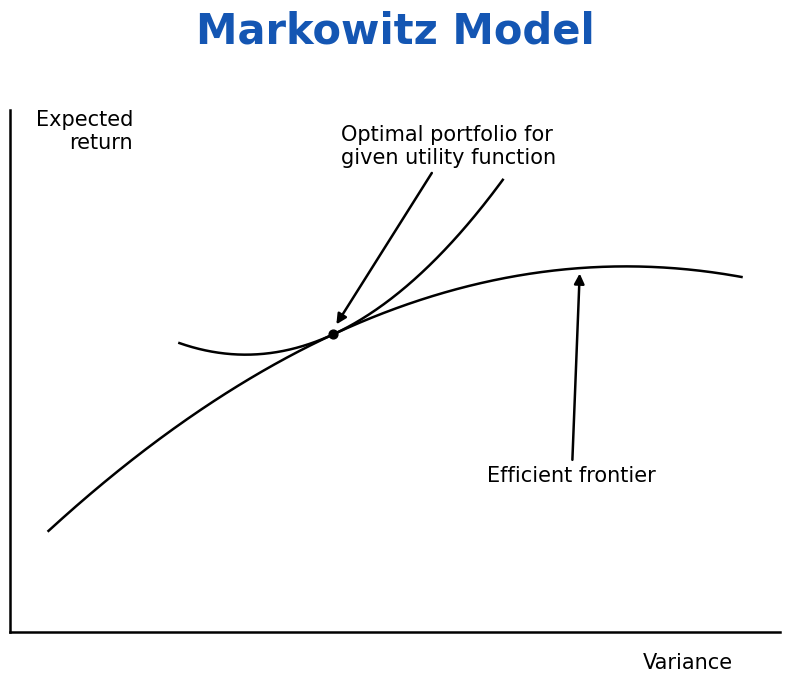

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- shape settings (arbitrary units) ----------------
v_top, r_top, k = 0.80, 0.70, 0.90     # peak of the frontier and how sharply it bends
v_star          = 0.42                 # variance of the optimal portfolio (tangency point)
curv            = 3.0                  # curvature of the utility (indifference) curve
SHOW_GUIDES     = False                # True -> dotted lines from the optimal point to both axes

def frontier(v):                       # concave efficient frontier
    return r_top - k * (v - v_top) ** 2

def frontier_slope(v):
    return -2 * k * (v - v_top)

r_star = frontier(v_star)
m_star = frontier_slope(v_star)

v_f = np.linspace(0.05, 0.95, 400)                 # efficient frontier
v_u = np.linspace(0.22, 0.64, 300)                 # utility curve, tangent to the frontier at v_star
u   = r_star + m_star * (v_u - v_star) + curv * (v_u - v_star) ** 2

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(v_f, frontier(v_f), color="black", lw=1.8)
ax.plot(v_u, u, color="black", lw=1.8)
ax.scatter([v_star], [r_star], color="black", s=40, zorder=5)

if SHOW_GUIDES:
    ax.plot([v_star, v_star], [0, r_star], color="grey", ls=":", lw=1)
    ax.plot([0, v_star], [r_star, r_star], color="grey", ls=":", lw=1)

ax.annotate("Optimal portfolio for\ngiven utility function", xy=(v_star, r_star + 0.01),
            xytext=(0.43, 0.93), fontsize=15, ha="left", va="center",
            arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8, shrinkA=2, shrinkB=4))
ax.annotate("Efficient frontier", xy=(0.74, frontier(0.74) - 0.005), xytext=(0.62, 0.30),
            fontsize=15, ha="left", va="center",
            arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8, shrinkA=2, shrinkB=2))

ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.0)
ax.set_xticks([]); ax.set_yticks([])
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.8); ax.spines["bottom"].set_linewidth(1.8)
ax.set_ylabel("Expected\nreturn", rotation=0, fontsize=15, ha="right", va="top")
ax.yaxis.set_label_coords(0.16, 1.0)
ax.set_xlabel("Variance", fontsize=15)
ax.xaxis.set_label_coords(0.88, -0.04)
fig.suptitle("Markowitz Model", fontsize=30, fontweight="bold", color="#1456b3", y=0.97)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("markowitz_schematic.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)
risk-free 0.0% | weight cap 30% | gamma 4 | covariance: sample


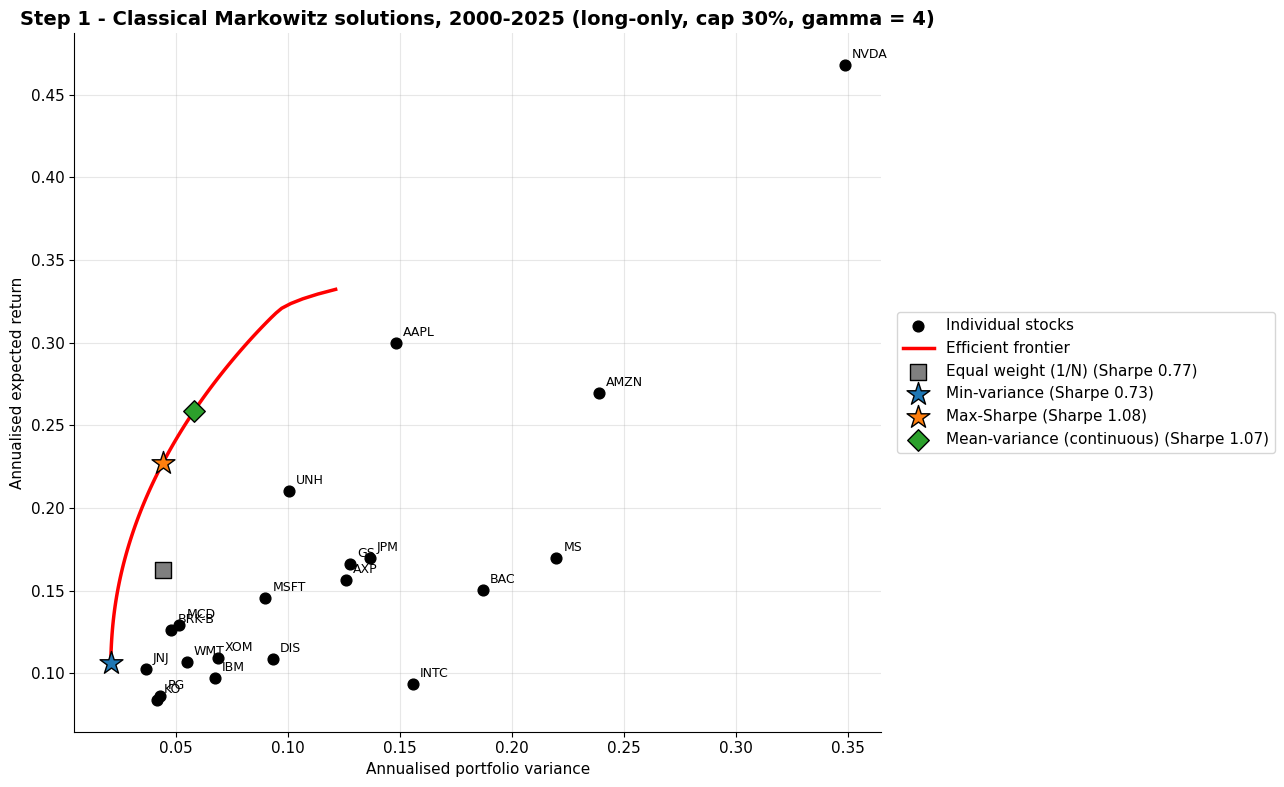

,Exp. return (%),Variance,Volatility (%),Sharpe,Stocks held (>0.5%)
Equal weight (1/N),16.2444,0.0441,21.0050,0.7734,20
Min-variance,10.6308,0.0210,14.4868,0.7338,9
Max-Sharpe,22.7163,0.0442,21.0181,1.0808,9
Mean-variance (continuous),25.8708,0.0582,24.1162,1.0728,7


Check passed: QUBO energy == mean-variance objective + penalty for 200 random bit strings (both formulations).

QUBO-W : 20 stocks x 3 bits = 60 binary variables | one unit = 5.0% | bit weights (units) = [1, 2, 3] | max weight per stock = 30%
QUBO-S : 20 binary variables (1 = stock selected), exactly K = 8 stocks held with equal weight 1/K
Penalty strengths: P(W) = 27.89, P(S) = 0.117


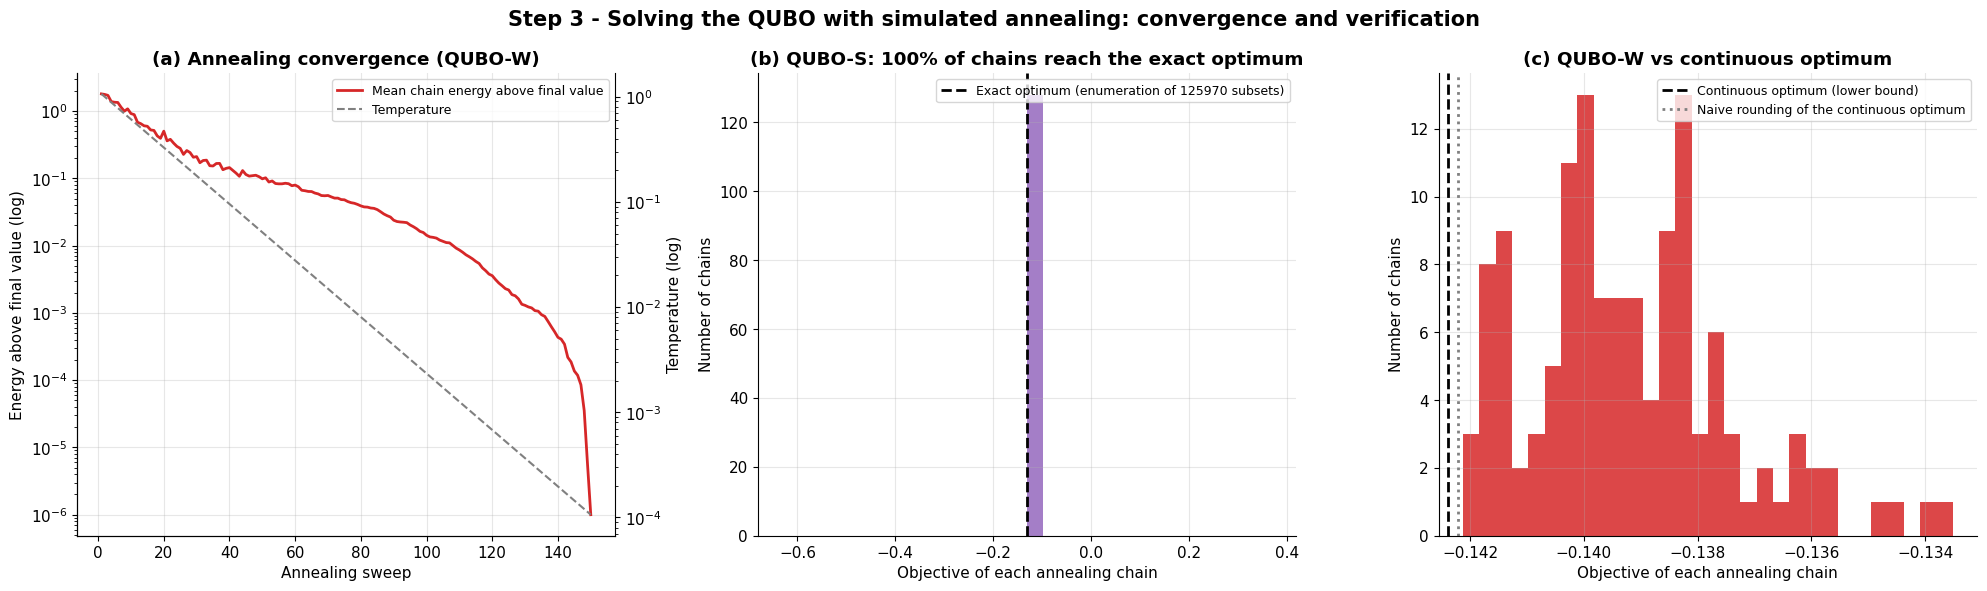

,value
QUBO-S: best objective found,-0.130984
QUBO-S: exact optimum,-0.130984
QUBO-S: same stocks as exact optimum,True
QUBO-S: chains reaching exact optimum (%),100.0
QUBO-W: objective,-0.14212
Continuous optimum (lower bound),-0.14239
QUBO-W: utility loss vs continuous optimum (pp of annual return),0.026985
Naive rounding: utility loss vs continuous (pp of annual return),0.018212
QUBO-W: chains ending budget-feasible (%),100.0
QUBO-W: best single-unit swap gain (0 = swap-optimal),-0.000088


Portfolio comparison (all strategies see the same expected returns and covariance matrix):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective (gamma=4),Stocks held (>0.5%),Largest weight (%),Effective N (1/sum w^2),Solve time (s)
EW,16.2444,0.0441,21.0050,0.7734,-0.0742,20.0,5.0000,20.0000,NaN
MinVar,10.6308,0.0210,14.4868,0.7338,-0.0643,9.0,23.9324,6.3883,NaN
MaxSharpe,22.7163,0.0442,21.0181,1.0808,-0.1388,9.0,19.7904,6.7191,NaN
MeanVar,25.8708,0.0582,24.1162,1.0728,-0.1424,7.0,25.2267,5.4848,0.0170
QUBO-W,25.4185,0.0560,23.6711,1.0738,-0.1421,7.0,25.0000,5.5556,1.1740
QUBO-S,21.3995,0.0415,20.3729,1.0504,-0.1310,8.0,12.5000,8.0000,0.2695


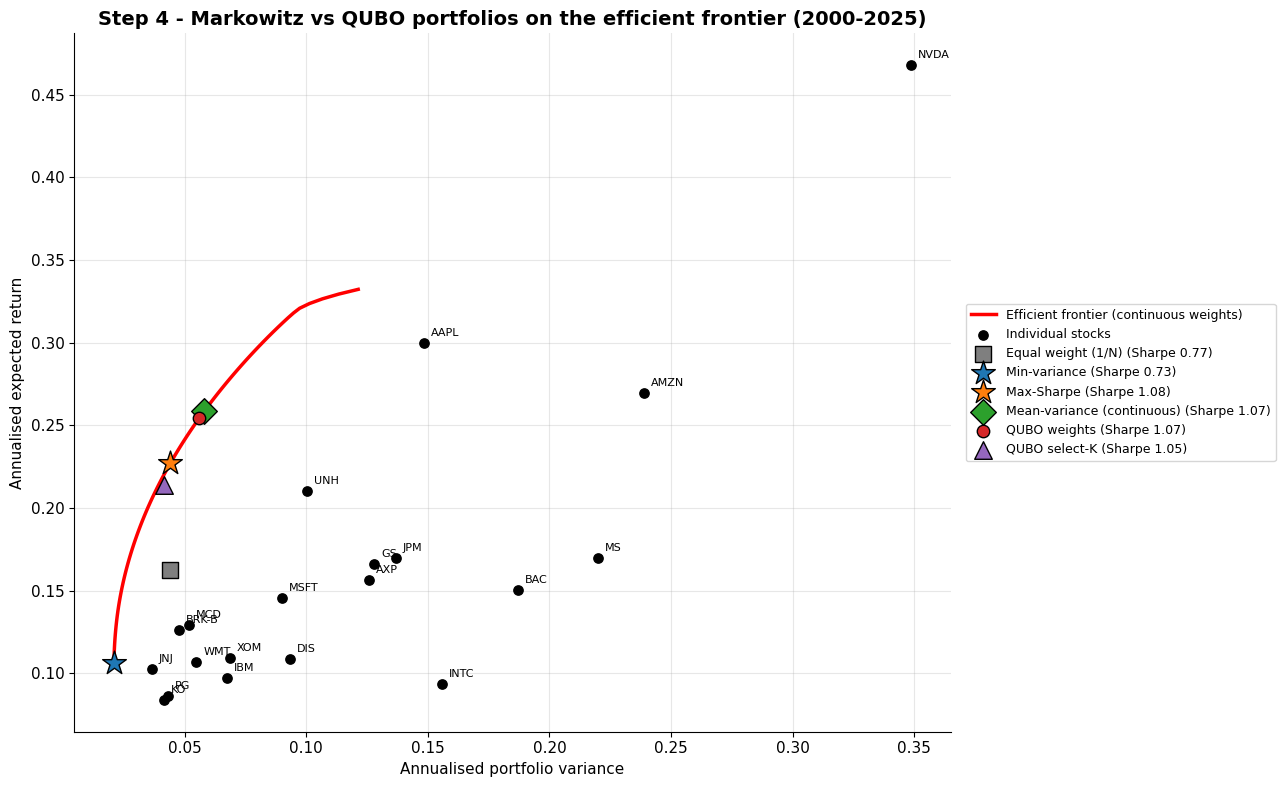

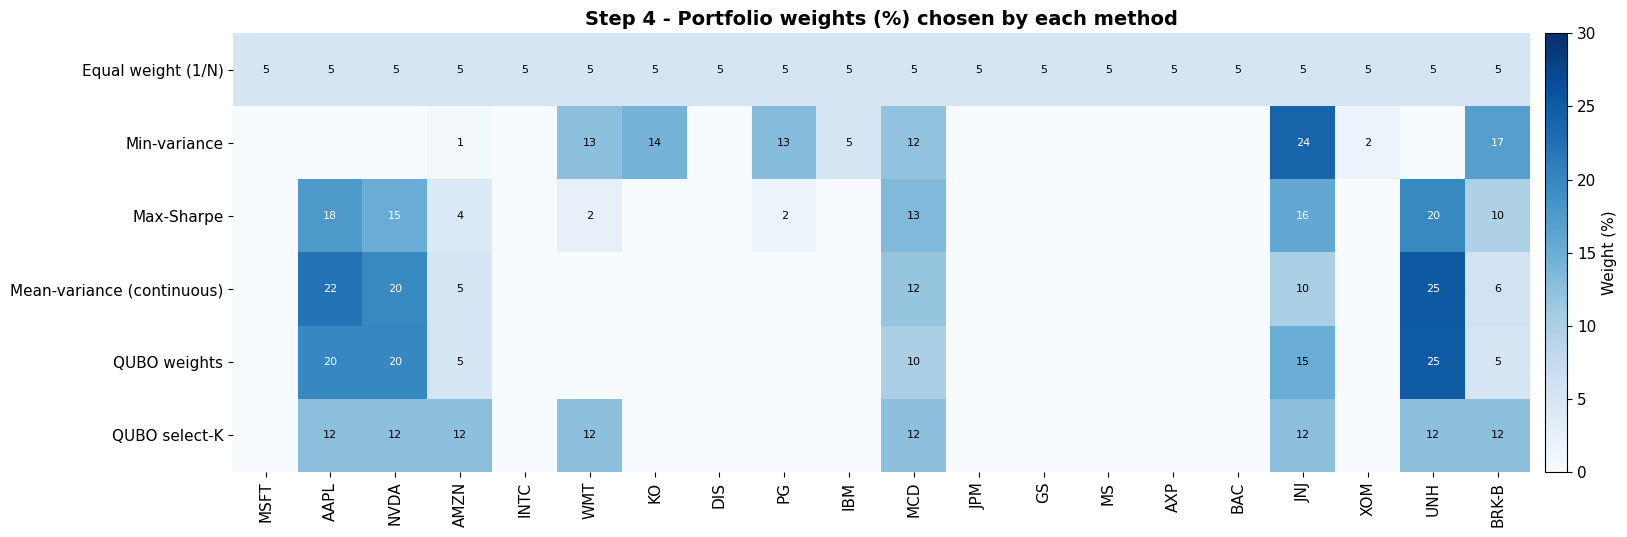

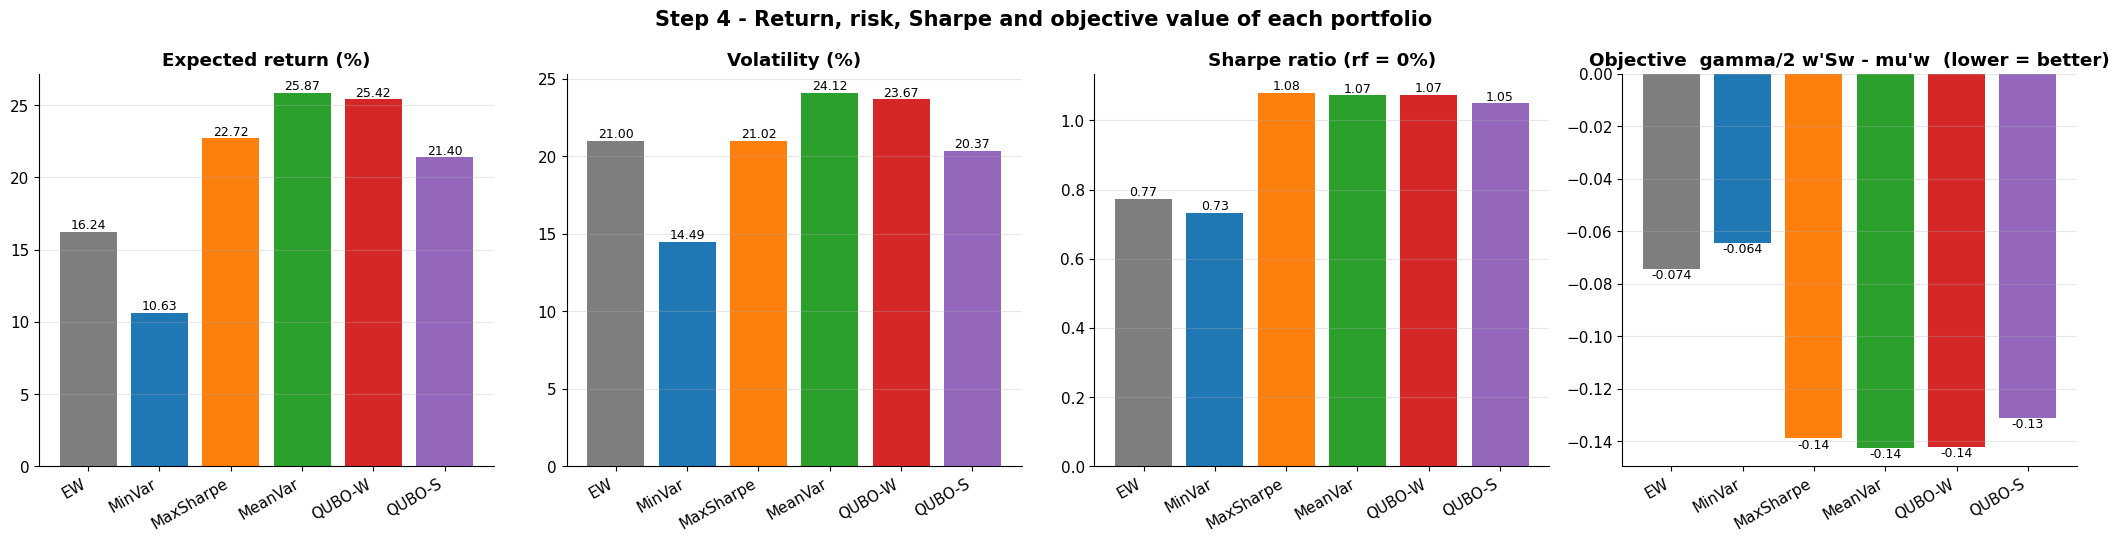

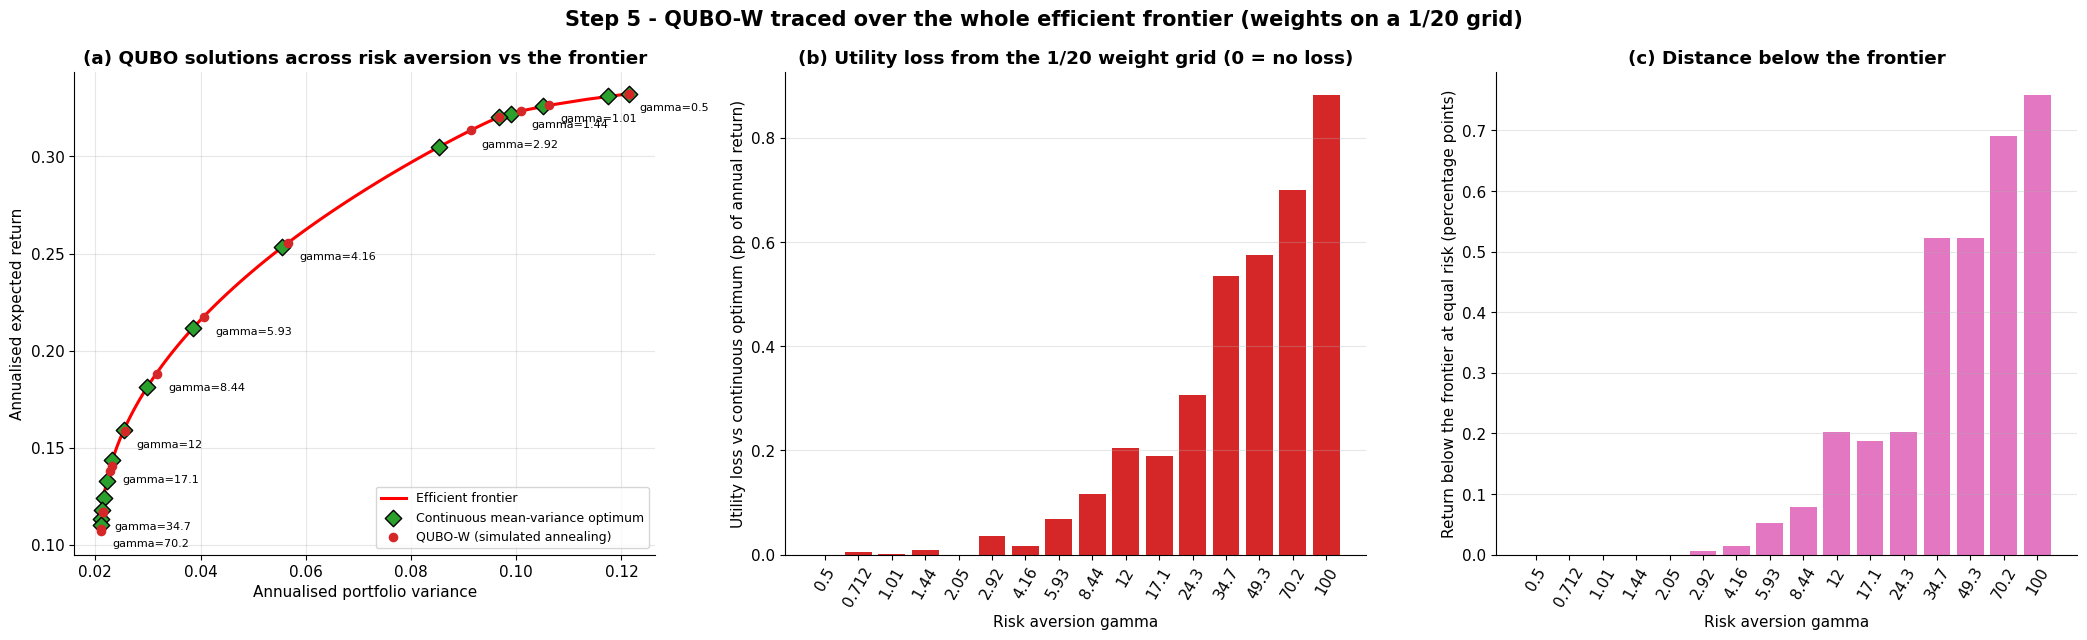

,ret_cont,var_cont,sharpe_cont,ret_qubo,var_qubo,sharpe_qubo,loss_pp,shortfall_pp,stocks_cont,stocks_qubo
gamma,,,,,,,,,,
0.500000,0.3323,0.1214,0.9538,0.3323,0.1214,0.9538,-0.0000,-0.0000,4,4
0.711823,0.3309,0.1175,0.9655,0.3323,0.1214,0.9538,0.0051,-0.0000,4,4
1.013384,0.3258,0.1051,1.0050,0.3263,0.1063,1.0011,0.0014,0.0000,4,4
1.442700,0.3221,0.0989,1.0241,0.3234,0.1008,1.0184,0.0095,0.0000,4,4
2.053894,0.3204,0.0968,1.0298,0.3204,0.0968,1.0298,0.0000,-0.0000,4,4
2.924018,0.3048,0.0852,1.0440,0.3134,0.0913,1.0369,0.0355,0.0061,5,5
4.162766,0.2534,0.0556,1.0751,0.2555,0.0567,1.0735,0.0167,0.0148,7,7
5.926305,0.2119,0.0386,1.0781,0.2172,0.0406,1.0772,0.0685,0.0518,9,9
8.436960,0.1814,0.0299,1.0492,0.1881,0.0318,1.0555,0.1166,0.0793,10,10


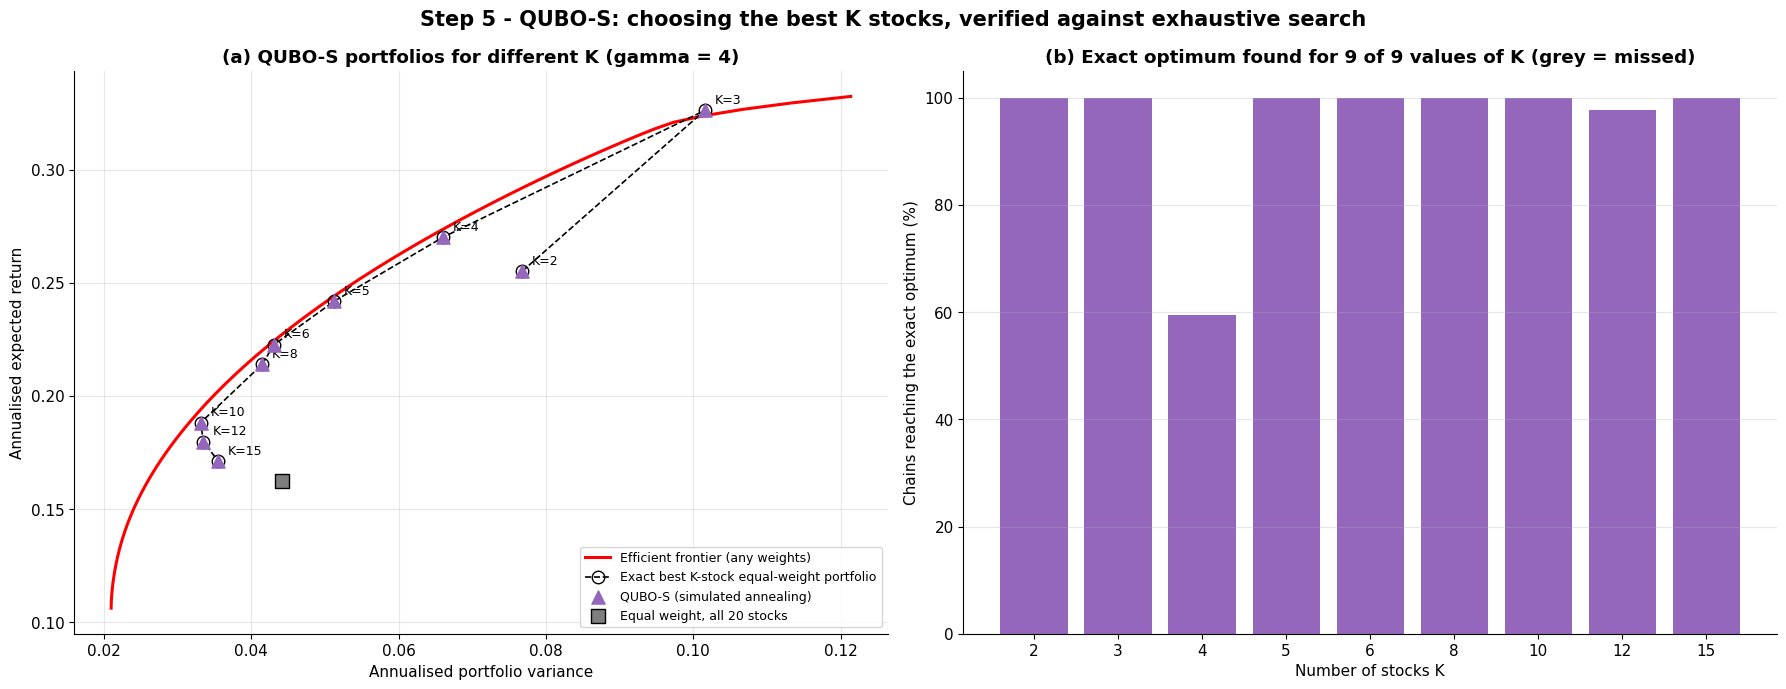

,ret_qubo,var_qubo,sharpe_qubo,ret_exact,var_exact,sharpe_exact,found_exact,chain_hit_pct,shortfall_pp
K,,,,,,,,,
2,0.2551,0.0768,0.9206,0.2551,0.0768,0.9206,True,100.0000,3.6772
3,0.3261,0.1015,1.0232,0.3261,0.1015,1.0232,True,100.0000,-0.2243
4,0.2701,0.0660,1.0511,0.2701,0.0660,1.0511,True,59.3750,0.3520
5,0.2419,0.0513,1.0681,0.2419,0.0513,1.0681,True,100.0000,0.2287
6,0.2226,0.0431,1.0726,0.2226,0.0431,1.0726,True,100.0000,0.1679
8,0.2140,0.0415,1.0504,0.2140,0.0415,1.0504,True,100.0000,0.6083
10,0.1882,0.0331,1.0339,0.1882,0.0331,1.0339,True,100.0000,0.5808
12,0.1798,0.0335,0.9821,0.1798,0.0335,0.9821,True,97.6562,1.5569
15,0.1713,0.0355,0.9092,0.1713,0.0355,0.9092,True,100.0000,3.0833


Robustness runs finished in 50 s



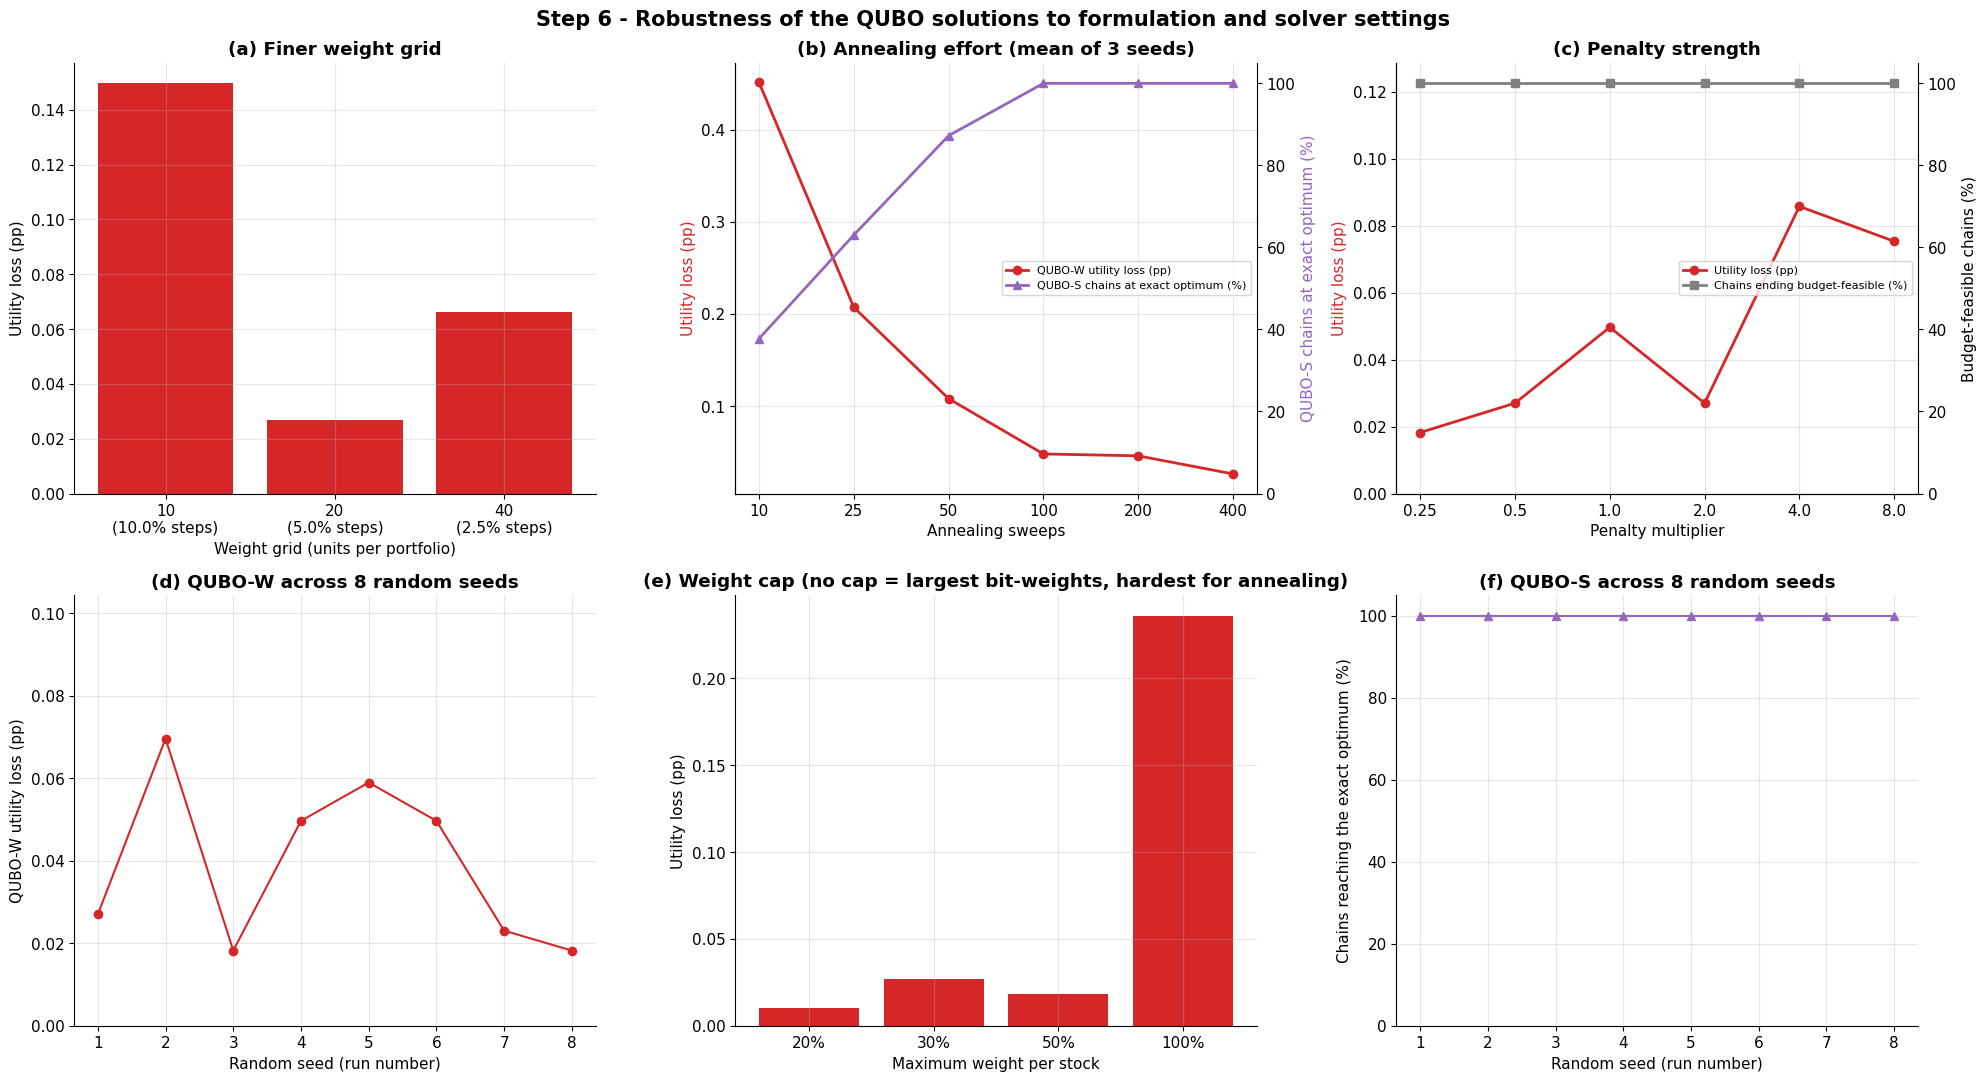

value
grid: utility loss (pp)  10.00     0.1496
                         20.00     0.0270
                         40.00     0.0663
sweeps: QUBO-W loss (pp) 10.00     0.4512
                         25.00     0.2072
                         50.00     0.1081
                         100.00    0.0481
                         200.00    0.0461
                         400.00    0.0264
sweeps: QUBO-S hit (%)   10.00    37.7604
                         25.00    63.0208
                         50.00    87.2396
                         100.00  100.0000
                         200.00  100.0000
                         400.00  100.0000
penalty: loss (pp)       0.25      0.0182
                         0.50      0.0270
                         1.00      0.0496
                         2.00      0.0270
                         4.00      0.0857
                         8.00      0.0753
penalty: feasible (%)    0.25    100.0000
                         0.50    100.0000
                         1.00    100.0000
                         2.00    100.0000
                         4.00    100.0000
                         8.00    100.0000
cap: utility loss (pp)   0.20      0.0103
                         0.30      0.0270
                         0.50      0.0182
                         1.00      0.2362

Seeds - QUBO-W loss (pp): mean 0.0393, max 0.0696 | QUBO-S chains at exact optimum (%): mean 100.0, min 100.0
QUBO-W (gamma = 4, 5% weight steps, cap 30%)
  utility loss vs continuous mean-variance optimum : 0.0270 pp of annual return
  naive rounding of the continuous optimum         : 0.0182 pp
  expected return / volatility / Sharpe            : 25.42% / 23.67% / 1.07  (continuous: 25.87% / 24.12% / 1.07)
QUBO-S (K = 8)
  exact optimum from exhaustive search found       : yes (100% of annealing chains reach it)
  across K = 2..15: exact optimum found for 9 of 9 values of K
Solve time: continuous 17 ms | QUBO-W annealing 1.2 s | QUBO-S annealing 0.3 s | exhaustive search 0.2 s
Reading guide: the QUBO matches the classical optimum only up to the resolution of its weight grid; the classical solver is
faster. The value of the QUBO route is that it also handles constraints classical convex solvers cannot (e.g. 'exactly K stocks').

All figures (PNG, 300 dpi) and tables (CSV) are saved in

In [2]:
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan

t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

fig, ax = plt.subplots(figsize=(13, 8))
if SHOW_RANDOM:
    rw = np.random.default_rng(SEED).dirichlet(np.ones(N), size=10000)
    rw = rw[rw.max(axis=1) <= MAX_W]
    r_ret, r_var = rw @ mu, np.einsum("ij,jk,ik->i", rw, Sigma, rw)
    sc = ax.scatter(xs(r_var), r_ret, c=(r_ret - RF) / np.sqrt(r_var), cmap="viridis", s=8, alpha=0.25, label="Random portfolios")
    plt.colorbar(sc, ax=ax, label="Sharpe ratio")
ax.scatter(xs(np.diag(Sigma)), mu, color="black", s=60, zorder=4, label="Individual stocks")
for t, v, r in zip(tickers, np.diag(Sigma), mu):
    ax.annotate(t, (xs(v), r), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label="Efficient frontier")
for name, w, mk, sz in [("EW", w_ew, "s", 120), ("MinVar", w_minvar, "*", 300), ("MaxSharpe", w_maxsh, "*", 300), ("MeanVar", w_meanvar, "D", 120)]:
    r_, v_, _, s_ = port_stats(w)
    ax.scatter(xs(v_), r_, color=COLORS[name], marker=mk, s=sz, edgecolor="black", zorder=6, label=f"{LABELS[name]} (Sharpe {s_:.2f})")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title(f"Step 1 - Classical Markowitz solutions, {returns.index[0].year}-{returns.index[-1].year} "
             f"(long-only, cap {MAX_W:.0%}, gamma = {GAMMA:g})", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("step1_markowitz_frontier"); plt.show()

tab = pd.DataFrame({LABELS[n]: dict(zip(["Exp. return (%)", "Variance", "Volatility (%)", "Sharpe"],
                                        [port_stats(w)[0] * 100, port_stats(w)[1], port_stats(w)[2] * 100, port_stats(w)[3]]))
                    for n, w in [("EW", w_ew), ("MinVar", w_minvar), ("MaxSharpe", w_maxsh), ("MeanVar", w_meanvar)]}).T
tab["Stocks held (>0.5%)"] = [int((w > 0.005).sum()) for w in (w_ew, w_minvar, w_maxsh, w_meanvar)]
display(tab.round(4))


# =============================================================================
# CELL 4 | STEP 2: QUBO formulation
#
# QUBO-W (weight encoding)    w_i = (sum_k a_k x_ik) / UNITS    with binary bits x_ik
#   minimise  gamma/2 w'Sigma w - mu'w + P (sum(w) - 1)^2   ->   energy(x) = x'Qx + const
#   Q = gamma/2 A'Sigma A - diag(A'mu) + P (c c' - 2 diag(c)),   A maps bits to weights, c = A'1.
#   The bit weights a_k are chosen so that no stock can exceed the weight cap.
#
# QUBO-S (select K stocks)    z_i in {0,1}, w_i = z_i / K
#   minimise  gamma/2 w'Sigma w - mu'w + P (sum(z) - K)^2
# =============================================================================
def bit_weights(cap_units):
    """Bounded binary encoding: bit weights sum to cap_units and reach every integer 0..cap_units."""
    m = int(np.floor(np.log2(cap_units)))
    return np.array([2 ** k for k in range(m)] + [cap_units - (2 ** m - 1)], dtype=float)

def build_qubo_weights(mu, Sigma, gamma, units, cap, pen_mult):
    n = len(mu)
    cap_u = int(np.floor(cap * units + 1e-9))
    a = bit_weights(cap_u)
    nb = len(a)
    A = np.zeros((n, n * nb))
    for i in range(n):
        A[i, i * nb:(i + 1) * nb] = a / units
    c = A.sum(axis=0)
    scale = max(np.abs(mu).max(), 0.5 * gamma * np.diag(Sigma).max())
    P = pen_mult * scale * units                       # breaking the budget by one unit must cost more than it can gain
    Q = 0.5 * gamma * (A.T @ Sigma @ A) - np.diag(A.T @ mu) + P * (np.outer(c, c) - 2 * np.diag(c))
    return dict(Q=Q, const=P, A=A, a=a, nb=nb, n=n, cap_u=cap_u, units=units, P=P)

def build_qubo_select(mu, Sigma, gamma, k, pen_mult):
    n = len(mu)
    P = pen_mult * max(np.abs(mu).max() / k, 0.5 * gamma * np.diag(Sigma).max() / k ** 2)
    Q = 0.5 * gamma / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

qw = build_qubo_weights(mu, Sigma, GAMMA, UNITS, MAX_W, PEN_MULT)
qs = build_qubo_select(mu, Sigma, GAMMA, K_SELECT, PEN_MULT)

# correctness check: the QUBO energy must equal the original objective + penalty for ANY bit string
rng_c = np.random.default_rng(1)
for _ in range(200):
    x = rng_c.integers(0, 2, qw["Q"].shape[0]).astype(float)
    w = qw["A"] @ x
    assert np.isclose(x @ qw["Q"] @ x + qw["const"], mv_objective(w, mu, Sigma, GAMMA) + qw["P"] * (w.sum() - 1) ** 2)
    z = rng_c.integers(0, 2, N).astype(float)
    assert np.isclose(z @ qs["Q"] @ z + qs["const"], mv_objective(z / K_SELECT, mu, Sigma, GAMMA) + qs["P"] * (z.sum() - K_SELECT) ** 2)
print("Check passed: QUBO energy == mean-variance objective + penalty for 200 random bit strings (both formulations).\n")

print(f"QUBO-W : {N} stocks x {qw['nb']} bits = {qw['Q'].shape[0]} binary variables | one unit = {100 / UNITS:.1f}% | "
      f"bit weights (units) = {qw['a'].astype(int).tolist()} | max weight per stock = {qw['cap_u'] / UNITS:.0%}")
print(f"QUBO-S : {N} binary variables (1 = stock selected), exactly K = {K_SELECT} stocks held with equal weight 1/K")
print(f"Penalty strengths: P(W) = {qw['P']:.2f}, P(S) = {qs['P']:.3f}")


# =============================================================================
# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f

def round_to_grid(w_cont, q, mu, Sigma, gamma):
    """Naive classical baseline: round the continuous optimum down to the weight grid, then repair the budget."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    u0 = np.minimum(np.floor(w_cont * U + 1e-9).astype(int), q["cap_u"])
    return repair_units(u0, f, U, q["cap_u"]) / U

def best_swap_gain(w, q, mu, Sigma, gamma):
    """Best objective change from moving ONE unit between any two stocks (>= 0 means 'no single swap helps')."""
    U = q["units"]
    u = np.rint(w * U).astype(int)
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    base, best = f(u), 0.0
    for i in range(len(u)):
        for j in range(len(u)):
            if i != j and u[i] > 0 and u[j] < q["cap_u"]:
                v = u.copy(); v[i] -= 1; v[j] += 1
                best = min(best, f(v) - base)
    return best


# =============================================================================
# CELL 6 | STEP 3 (continued): solve both QUBOs once and verify the solutions
#   QUBO-S  : compared with the EXACT optimum from exhaustive enumeration of all C(N,K) portfolios
#   QUBO-W  : compared with the continuous mean-variance optimum (lower bound), a naive rounding baseline,
#             and a single-swap local-optimality check
# =============================================================================
rng_s = np.random.default_rng(SEED)

t0 = time.time()
Xw, Ew, (temps, trace) = simulated_annealing(qw["Q"], SA_CHAINS, SA_SWEEPS, rng=rng_s)
w_qw, info_w = decode_weights(Xw, Ew, qw, mu, Sigma, GAMMA)
t_qw = time.time() - t0

t0 = time.time()
Xs, Es, _ = simulated_annealing(qs["Q"], SA_CHAINS, SA_SWEEPS, rng=rng_s)
w_qs, info_s = decode_select(Xs, Es, qs, mu, Sigma, GAMMA)
t_qs = time.time() - t0

t0 = time.time()
sel_exact, f_exact = exact_select(mu, Sigma, GAMMA, K_SELECT)
t_exact = time.time() - t0

f_cont = mv_objective(w_meanvar, mu, Sigma, GAMMA)
f_qw = mv_objective(w_qw, mu, Sigma, GAMMA)
f_qs = mv_objective(w_qs, mu, Sigma, GAMMA)
w_round = round_to_grid(w_meanvar, qw, mu, Sigma, GAMMA)
f_round = mv_objective(w_round, mu, Sigma, GAMMA)
swap_gain = best_swap_gain(w_qw, qw, mu, Sigma, GAMMA)
obj_w_chains = chain_objectives_w(Xw, qw, mu, Sigma, GAMMA)
obj_s_chains = chain_objectives_s(Xs, qs, mu, Sigma, GAMMA)
hit_rate = float(np.mean(obj_s_chains <= f_exact + 1e-10))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
ax = axes[0]
ax.plot(np.arange(1, SA_SWEEPS + 1), trace - trace.min() + 1e-6, color=COLORS["QUBO-W"], lw=2, label="Mean chain energy above final value")
ax.set_yscale("log"); ax.set_xlabel("Annealing sweep"); ax.set_ylabel("Energy above final value (log)")
ax2 = ax.twinx(); ax2.plot(np.arange(1, SA_SWEEPS + 1), temps, color="grey", ls="--", label="Temperature")
ax2.set_yscale("log"); ax2.set_ylabel("Temperature (log)"); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=9)
ax.set_title("(a) Annealing convergence (QUBO-W)", fontweight="bold"); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.hist(obj_s_chains, bins=30, color=COLORS["QUBO-S"], alpha=0.85)
ax.axvline(f_exact, color="black", lw=2, ls="--", label=f"Exact optimum (enumeration of {int(np.round(np.exp(np.sum(np.log(np.arange(N - K_SELECT + 1, N + 1)) - np.log(np.arange(1, K_SELECT + 1))))))} subsets)")
ax.set_xlabel("Objective of each annealing chain"); ax.set_ylabel("Number of chains")
ax.set_title(f"(b) QUBO-S: {hit_rate:.0%} of chains reach the exact optimum", fontweight="bold"); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[2]
ax.hist(obj_w_chains, bins=30, color=COLORS["QUBO-W"], alpha=0.85)
ax.axvline(f_cont, color="black", lw=2, ls="--", label="Continuous optimum (lower bound)")
ax.axvline(f_round, color="grey", lw=2, ls=":", label="Naive rounding of the continuous optimum")
ax.set_xlabel("Objective of each annealing chain"); ax.set_ylabel("Number of chains")
ax.set_title("(c) QUBO-W vs continuous optimum", fontweight="bold"); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
fig.suptitle("Step 3 - Solving the QUBO with simulated annealing: convergence and verification", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step3_solver_verification"); plt.show()

ver = pd.DataFrame({
    "QUBO-S: best objective found": [f_qs], "QUBO-S: exact optimum": [f_exact],
    "QUBO-S: same stocks as exact optimum": [bool(set(np.flatnonzero(w_qs > 0)) == set(sel_exact))],
    "QUBO-S: chains reaching exact optimum (%)": [hit_rate * 100],
    "QUBO-W: objective": [f_qw], "Continuous optimum (lower bound)": [f_cont],
    "QUBO-W: utility loss vs continuous optimum (pp of annual return)": [(f_qw - f_cont) * 100],
    "Naive rounding: utility loss vs continuous (pp of annual return)": [(f_round - f_cont) * 100],
    "QUBO-W: chains ending budget-feasible (%)": [info_w["feasible_rate"] * 100],
    "QUBO-W: best single-unit swap gain (0 = swap-optimal)": [swap_gain],
}, index=["value"]).T
display(ver.round(6))


# =============================================================================
# CELL 7 | STEP 4: Comparison of the Markowitz and QUBO portfolios (same mu, Sigma, same objective)
# =============================================================================
PORTS = {"EW": w_ew, "MinVar": w_minvar, "MaxSharpe": w_maxsh, "MeanVar": w_meanvar, "QUBO-W": w_qw, "QUBO-S": w_qs}
SOLVE_TIME = {"EW": np.nan, "MinVar": np.nan, "MaxSharpe": np.nan, "MeanVar": t_meanvar, "QUBO-W": t_qw, "QUBO-S": t_qs}

rows = {}
for s, w in PORTS.items():
    ret, var, vol, sh = port_stats(w)
    rows[s] = {"Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
               f"Objective (gamma={GAMMA:g})": mv_objective(w, mu, Sigma, GAMMA),
               "Stocks held (>0.5%)": int((w > 0.005).sum()), "Largest weight (%)": w.max() * 100,
               "Effective N (1/sum w^2)": 1 / np.sum(w ** 2), "Solve time (s)": SOLVE_TIME[s]}
COMP = pd.DataFrame(rows).T
print("Portfolio comparison (all strategies see the same expected returns and covariance matrix):")
display(COMP.round(4))

# ---- Figure A: frontier with every portfolio ----
fig, ax = plt.subplots(figsize=(13, 8))
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label="Efficient frontier (continuous weights)")
ax.scatter(xs(np.diag(Sigma)), mu, color="black", s=45, zorder=3, label="Individual stocks")
for t, v, r in zip(tickers, np.diag(Sigma), mu):
    ax.annotate(t, (xs(v), r), xytext=(5, 5), textcoords="offset points", fontsize=8)
style = {"EW": ("s", 120, 5), "MinVar": ("*", 320, 6), "MaxSharpe": ("*", 320, 6), "MeanVar": ("D", 170, 7), "QUBO-W": ("o", 80, 8), "QUBO-S": ("^", 160, 8)}
for s, w in PORTS.items():
    r_, v_, _, sh = port_stats(w)
    mk, sz, z = style[s]
    ax.scatter(xs(v_), r_, color=COLORS[s], marker=mk, s=sz, edgecolor="black", zorder=z, label=f"{LABELS[s]} (Sharpe {sh:.2f})")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.set_title(f"Step 4 - Markowitz vs QUBO portfolios on the efficient frontier ({returns.index[0].year}-{returns.index[-1].year})",
             fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("step4a_frontier_with_portfolios"); plt.show()

# ---- Figure B: weights of every strategy ----
W_DF = pd.DataFrame(PORTS, index=tickers).T * 100
fig, ax = plt.subplots(figsize=(18, 5.5))
im = ax.imshow(W_DF.values, aspect="auto", cmap="Blues", vmin=0, vmax=max(MAX_W * 100, W_DF.values.max()))
ax.set_xticks(range(N)); ax.set_xticklabels(tickers, rotation=90)
ax.set_yticks(range(len(W_DF))); ax.set_yticklabels([LABELS[s] for s in W_DF.index])
for i in range(W_DF.shape[0]):
    for j in range(N):
        v = W_DF.iat[i, j]
        if v > 0.5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * W_DF.values.max() else "black")
plt.colorbar(im, ax=ax, pad=0.01, label="Weight (%)")
ax.set_title("Step 4 - Portfolio weights (%) chosen by each method", fontsize=14, fontweight="bold")
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); savefig("step4b_weights"); plt.show()

# ---- Figure C: key numbers ----
fig, axes = plt.subplots(1, 4, figsize=(21, 5.5))
for ax, (col, title) in zip(axes, [("Exp. return (%)", "Expected return (%)"), ("Volatility (%)", "Volatility (%)"),
                                   ("Sharpe", f"Sharpe ratio (rf = {RF:.0%})"), (f"Objective (gamma={GAMMA:g})", f"Objective  gamma/2 w'Sw - mu'w  (lower = better)")]):
    vals = COMP[col].astype(float)
    ax.bar(range(len(vals)), vals, color=[COLORS[s] for s in vals.index])
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(vals.index, rotation=30, ha="right")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}" if abs(v) >= 0.1 else f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    ax.set_title(title, fontweight="bold"); ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Step 4 - Return, risk, Sharpe and objective value of each portfolio", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step4c_metric_bars"); plt.show()


# =============================================================================
# CELL 8 | STEP 5: Does the QUBO trace the whole efficient frontier?
#   (a) QUBO-W: repeat the optimisation for a range of risk aversions gamma and compare with the exact continuous frontier
#   (b) QUBO-S: repeat for K = 2 ... 15 stocks and compare with the exhaustive-search optimum
# =============================================================================
GAMMAS = np.geomspace(0.5, 100, 8 if QUICK else 16)
rows = []
for gm in GAMMAS:
    wc = mean_variance(mu, Sigma, gm, MAX_W)
    q = build_qubo_weights(mu, Sigma, gm, UNITS, MAX_W, PEN_MULT)
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + int(gm * 100)))
    wq, _ = decode_weights(X, E, q, mu, Sigma, gm)
    fc, fq = mv_objective(wc, mu, Sigma, gm), mv_objective(wq, mu, Sigma, gm)
    rc, vc, _, shc = port_stats(wc)
    rq, vq, _, shq = port_stats(wq)
    rows.append(dict(gamma=gm, ret_cont=rc, var_cont=vc, sharpe_cont=shc, ret_qubo=rq, var_qubo=vq, sharpe_qubo=shq,
                     loss_pp=(fq - fc) * 100,
                     shortfall_pp=(frontier_return_at(vq, mu, Sigma, MAX_W, w_minvar) - rq) * 100,   # return lost vs the frontier at the same risk
                     stocks_cont=int((wc > 0.005).sum()), stocks_qubo=int((wq > 0.005).sum())))
SWEEP_W = pd.DataFrame(rows).set_index("gamma")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.2, label="Efficient frontier")
ax.scatter(xs(SWEEP_W["var_cont"]), SWEEP_W["ret_cont"], color=COLORS["MeanVar"], marker="D", s=70, edgecolor="black", zorder=4, label="Continuous mean-variance optimum")
ax.scatter(xs(SWEEP_W["var_qubo"]), SWEEP_W["ret_qubo"], color=COLORS["QUBO-W"], s=35, zorder=5, label="QUBO-W (simulated annealing)")
seen = []
for gm, r in SWEEP_W.iterrows():                                   # label each distinct point once
    p = np.array([xs(r["var_qubo"]), r["ret_qubo"]])
    if all(np.abs(p - q_).max() > 0.02 * np.array([np.ptp(xs(f_var)), np.ptp(f_ret)]).max() for q_ in seen):
        seen.append(p)
        ax.annotate(f"gamma={gm:.3g}", p, xytext=(8, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(fontsize=9, loc="lower right")
ax.set_title("(a) QUBO solutions across risk aversion vs the frontier", fontweight="bold")
ax = axes[1]
ax.bar([f"{g_:.3g}" for g_ in SWEEP_W.index], SWEEP_W["loss_pp"], color=COLORS["QUBO-W"])
ax.set_xlabel("Risk aversion gamma"); ax.set_ylabel("Utility loss vs continuous optimum (pp of annual return)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("(b) Utility loss from the 1/%d weight grid (0 = no loss)" % UNITS, fontweight="bold"); ax.grid(True, axis="y", alpha=0.3)
ax = axes[2]
ax.bar([f"{g_:.3g}" for g_ in SWEEP_W.index], SWEEP_W["shortfall_pp"], color="#e377c2")
ax.set_xlabel("Risk aversion gamma"); ax.set_ylabel("Return below the frontier at equal risk (percentage points)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("(c) Distance below the frontier", fontweight="bold"); ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Step 5 - QUBO-W traced over the whole efficient frontier (weights on a 1/%d grid)" % UNITS, fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step5a_qubo_w_frontier_sweep"); plt.show()
display(SWEEP_W.round(4))

# ---------------- QUBO-S for several K ----------------
KS = [2, 3, 5, 8, 12] if QUICK else [2, 3, 4, 5, 6, 8, 10, 12, 15]
rows = []
for k in KS:
    q = build_qubo_select(mu, Sigma, GAMMA, k, PEN_MULT)
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + k))
    wq, _ = decode_select(X, E, q, mu, Sigma, GAMMA)
    sel, fex = exact_select(mu, Sigma, GAMMA, k)
    wex = np.zeros(N); wex[sel] = 1.0 / k
    chain_f = chain_objectives_s(X, q, mu, Sigma, GAMMA)
    rq, vq, _, shq = port_stats(wq)
    re, ve, _, she = port_stats(wex)
    rows.append(dict(K=k, ret_qubo=rq, var_qubo=vq, sharpe_qubo=shq, ret_exact=re, var_exact=ve, sharpe_exact=she,
                     found_exact=bool(mv_objective(wq, mu, Sigma, GAMMA) <= fex + 1e-10),
                     chain_hit_pct=float(np.mean(chain_f <= fex + 1e-10)) * 100,
                     shortfall_pp=(frontier_return_at(vq, mu, Sigma, MAX_W, w_minvar) - rq) * 100))
SWEEP_S = pd.DataFrame(rows).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.2, label="Efficient frontier (any weights)")
ax.plot(xs(SWEEP_S["var_exact"]), SWEEP_S["ret_exact"], color="black", lw=1.2, ls="--", marker="o", ms=9, mfc="none", label="Exact best K-stock equal-weight portfolio")
ax.scatter(xs(SWEEP_S["var_qubo"]), SWEEP_S["ret_qubo"], color=COLORS["QUBO-S"], marker="^", s=90, zorder=5, label="QUBO-S (simulated annealing)")
for k, r in SWEEP_S.iterrows():
    ax.annotate(f"K={k}", (xs(r["var_qubo"]), r["ret_qubo"]), xytext=(7, 5), textcoords="offset points", fontsize=9)
r_, v_, _, _ = port_stats(w_ew)
ax.scatter(xs(v_), r_, color=COLORS["EW"], marker="s", s=110, edgecolor="black", zorder=6, label="Equal weight, all 20 stocks")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(fontsize=9, loc="lower right")
ax.set_title(f"(a) QUBO-S portfolios for different K (gamma = {GAMMA:g})", fontweight="bold")
ax = axes[1]
ax.bar([str(k) for k in SWEEP_S.index], SWEEP_S["chain_hit_pct"], color=np.where(SWEEP_S["found_exact"], COLORS["QUBO-S"], "#bbbbbb"))
ax.set_xlabel("Number of stocks K"); ax.set_ylabel("Chains reaching the exact optimum (%)"); ax.set_ylim(0, 105)
ax.set_title(f"(b) Exact optimum found for {int(SWEEP_S['found_exact'].sum())} of {len(SWEEP_S)} values of K (grey = missed)", fontweight="bold")
ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Step 5 - QUBO-S: choosing the best K stocks, verified against exhaustive search", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step5b_qubo_s_k_sweep"); plt.show()
display(SWEEP_S.round(4))


# =============================================================================
# CELL 9 | STEP 6: Robustness - how much do the QUBO results depend on the modelling and solver choices?
#   (a) weight-grid size   (b) annealing effort   (c) penalty strength   (d) random seed   (e) weight cap
# All numbers are "utility loss vs the continuous optimum" in percentage points of annual return (0 = perfect).
# =============================================================================
N_SEEDS = 4 if QUICK else 8
UNITS_GRID = [10, 20, 40]
SWEEPS_GRID = [10, 25, 50, 100, 200] if QUICK else [10, 25, 50, 100, 200, 400]
PEN_GRID = [0.5, 2, 8] if QUICK else [0.25, 0.5, 1, 2, 4, 8]
CAP_GRID = [0.2, 0.3, 0.5] if QUICK else [0.2, 0.3, 0.5, 1.0]

def solve_w(gamma=GAMMA, units=UNITS, cap=MAX_W, pen=PEN_MULT, chains=SA_CHAINS, sweeps=SA_SWEEPS, seed=SEED):
    """One QUBO-W solve. Returns (utility loss in pp, share of budget-feasible chains)."""
    q = build_qubo_weights(mu, Sigma, gamma, units, cap, pen)
    X, E, _ = simulated_annealing(q["Q"], chains, sweeps, rng=np.random.default_rng(seed))
    w, info = decode_weights(X, E, q, mu, Sigma, gamma)
    wc = w_meanvar if (gamma == GAMMA and cap == MAX_W) else mean_variance(mu, Sigma, gamma, cap)
    return (mv_objective(w, mu, Sigma, gamma) - mv_objective(wc, mu, Sigma, gamma)) * 100, info["feasible_rate"] * 100

def solve_s(k=K_SELECT, pen=PEN_MULT, chains=SA_CHAINS, sweeps=SA_SWEEPS, seed=SEED, f_exact_k=None):
    """One QUBO-S solve. Returns share of chains that reach the exact optimum."""
    q = build_qubo_select(mu, Sigma, GAMMA, k, pen)
    X, E, _ = simulated_annealing(q["Q"], chains, sweeps, rng=np.random.default_rng(seed))
    return float(np.mean(chain_objectives_s(X, q, mu, Sigma, GAMMA) <= f_exact_k + 1e-10)) * 100

t0 = time.time()
rob = {}
rob["units"] = pd.Series({u: solve_w(units=u)[0] for u in UNITS_GRID})
res = {sw: [(solve_w(sweeps=sw, seed=SEED + s)[0], solve_s(sweeps=sw, seed=SEED + s, f_exact_k=f_exact)) for s in range(3)] for sw in SWEEPS_GRID}
rob["sweeps_w"] = pd.Series({sw: np.mean([r[0] for r in v]) for sw, v in res.items()})
rob["sweeps_s"] = pd.Series({sw: np.mean([r[1] for r in v]) for sw, v in res.items()})
pen_res = {p: solve_w(pen=p) for p in PEN_GRID}
rob["pen_loss"] = pd.Series({p: v[0] for p, v in pen_res.items()})
rob["pen_feas"] = pd.Series({p: v[1] for p, v in pen_res.items()})
seed_res = [solve_w(seed=SEED + 100 + s) for s in range(N_SEEDS)]
rob["seeds_w"] = pd.Series([r[0] for r in seed_res])
rob["seeds_s"] = pd.Series([solve_s(seed=SEED + 100 + s, f_exact_k=f_exact) for s in range(N_SEEDS)])
rob["cap"] = pd.Series({c: solve_w(cap=c)[0] for c in CAP_GRID})
print(f"Robustness runs finished in {time.time() - t0:.0f} s\n")

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
ax = axes[0, 0]
ax.bar([f"{u}\n({100 / u:.1f}% steps)" for u in rob["units"].index], rob["units"].values, color=COLORS["QUBO-W"])
ax.set_ylabel("Utility loss (pp)"); ax.set_xlabel("Weight grid (units per portfolio)"); ax.set_title("(a) Finer weight grid", fontweight="bold")
ax = axes[0, 1]
ax.plot(rob["sweeps_w"].index.astype(str), rob["sweeps_w"].values, marker="o", color=COLORS["QUBO-W"], lw=2, label="QUBO-W utility loss (pp)")
ax.set_xlabel("Annealing sweeps"); ax.set_ylabel("Utility loss (pp)", color=COLORS["QUBO-W"])
ax2 = ax.twinx(); ax2.plot(rob["sweeps_s"].index.astype(str), rob["sweeps_s"].values, marker="^", color=COLORS["QUBO-S"], lw=2, label="QUBO-S chains at exact optimum (%)")
ax2.set_ylabel("QUBO-S chains at exact optimum (%)", color=COLORS["QUBO-S"]); ax2.set_ylim(0, 105); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
ax.set_title("(b) Annealing effort (mean of 3 seeds)", fontweight="bold")
ax = axes[0, 2]
ax.plot([str(p) for p in rob["pen_loss"].index], rob["pen_loss"].values, marker="o", color=COLORS["QUBO-W"], lw=2, label="Utility loss (pp)")
ax.set_xlabel("Penalty multiplier"); ax.set_ylabel("Utility loss (pp)", color=COLORS["QUBO-W"])
ax2 = ax.twinx(); ax2.plot([str(p) for p in rob["pen_feas"].index], rob["pen_feas"].values, marker="s", color="grey", lw=2, label="Chains ending budget-feasible (%)")
ax2.set_ylabel("Budget-feasible chains (%)"); ax2.set_ylim(0, 105); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
ax.set_ylim(0, max(rob["pen_loss"].max() * 1.5, 0.01)); ax.set_title("(c) Penalty strength", fontweight="bold")
ax = axes[1, 0]
ax.plot(range(1, N_SEEDS + 1), rob["seeds_w"].values, marker="o", color=COLORS["QUBO-W"], lw=1.5)
ax.set_ylim(0, max(rob["seeds_w"].max() * 1.5, 0.01)); ax.set_xlabel("Random seed (run number)"); ax.set_ylabel("QUBO-W utility loss (pp)")
ax.set_title(f"(d) QUBO-W across {N_SEEDS} random seeds", fontweight="bold")
ax = axes[1, 1]
ax.bar([f"{c:.0%}" for c in rob["cap"].index], rob["cap"].values, color=COLORS["QUBO-W"])
ax.set_xlabel("Maximum weight per stock"); ax.set_ylabel("Utility loss (pp)")
ax.set_title("(e) Weight cap (no cap = largest bit-weights, hardest for annealing)", fontweight="bold")
ax = axes[1, 2]
ax.plot(range(1, N_SEEDS + 1), rob["seeds_s"].values, marker="^", color=COLORS["QUBO-S"], lw=1.5)
ax.set_ylim(0, 105); ax.set_xlabel("Random seed (run number)"); ax.set_ylabel("Chains reaching the exact optimum (%)")
ax.set_title(f"(f) QUBO-S across {N_SEEDS} random seeds", fontweight="bold")
for ax in axes.flat: ax.grid(True, alpha=0.3)
fig.suptitle("Step 6 - Robustness of the QUBO solutions to formulation and solver settings", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step6_robustness"); plt.show()

ROB_TABLE = pd.concat({"grid: utility loss (pp)": rob["units"], "sweeps: QUBO-W loss (pp)": rob["sweeps_w"],
                       "sweeps: QUBO-S hit (%)": rob["sweeps_s"], "penalty: loss (pp)": rob["pen_loss"],
                       "penalty: feasible (%)": rob["pen_feas"], "cap: utility loss (pp)": rob["cap"]})
display(ROB_TABLE.round(4).to_frame("value"))
print(f"Seeds - QUBO-W loss (pp): mean {rob['seeds_w'].mean():.4f}, max {rob['seeds_w'].max():.4f} | "
      f"QUBO-S chains at exact optimum (%): mean {rob['seeds_s'].mean():.1f}, min {rob['seeds_s'].min():.1f}")


# =============================================================================
# CELL 10 | STEP 7: Final summary and saving every table
# =============================================================================
COMP.to_csv(f"{OUT_DIR}/portfolio_comparison.csv")
W_DF.round(4).to_csv(f"{OUT_DIR}/portfolio_weights_percent.csv")
SWEEP_W.to_csv(f"{OUT_DIR}/qubo_w_gamma_sweep.csv")
SWEEP_S.to_csv(f"{OUT_DIR}/qubo_s_k_sweep.csv")
ROB_TABLE.to_csv(f"{OUT_DIR}/robustness.csv")
ver.to_csv(f"{OUT_DIR}/solver_verification.csv")

loss_pp = (f_qw - f_cont) * 100
print("=" * 78)
print(f"QUBO-W (gamma = {GAMMA:g}, {100 / UNITS:.0f}% weight steps, cap {MAX_W:.0%})")
print(f"  utility loss vs continuous mean-variance optimum : {loss_pp:.4f} pp of annual return")
print(f"  naive rounding of the continuous optimum         : {(f_round - f_cont) * 100:.4f} pp")
print(f"  expected return / volatility / Sharpe            : {COMP.loc['QUBO-W', 'Exp. return (%)']:.2f}% / "
      f"{COMP.loc['QUBO-W', 'Volatility (%)']:.2f}% / {COMP.loc['QUBO-W', 'Sharpe']:.2f}  "
      f"(continuous: {COMP.loc['MeanVar', 'Exp. return (%)']:.2f}% / {COMP.loc['MeanVar', 'Volatility (%)']:.2f}% / {COMP.loc['MeanVar', 'Sharpe']:.2f})")
print(f"QUBO-S (K = {K_SELECT})")
print(f"  exact optimum from exhaustive search found       : {'yes' if abs(f_qs - f_exact) < 1e-10 else 'NO'} "
      f"({hit_rate:.0%} of annealing chains reach it)")
print(f"  across K = {KS[0]}..{KS[-1]}: exact optimum found for {int(SWEEP_S['found_exact'].sum())} of {len(SWEEP_S)} values of K")
print(f"Solve time: continuous {t_meanvar * 1000:.0f} ms | QUBO-W annealing {t_qw:.1f} s | QUBO-S annealing {t_qs:.1f} s | exhaustive search {t_exact:.1f} s")
print("=" * 78)
print("Reading guide: the QUBO matches the classical optimum only up to the resolution of its weight grid; the classical solver is")
print("faster. The value of the QUBO route is that it also handles constraints classical convex solvers cannot (e.g. 'exactly K stocks').")
print(f"\nAll figures (PNG, 300 dpi) and tables (CSV) are saved in ./{OUT_DIR}/")

In [ ]:
# =============================================================================
# MIQP (Mixed-Integer Quadratic Programming) on the S&P 500 stocks, 2000-2025
#
# PART 1  Data collection : S&P 500 constituents from Wikipedia + daily prices from Yahoo Finance (yfinance)
# PART 2  Inputs          : full-period annualised mean return mu and covariance Sigma (no train/test split, no backtest)
# PART 3  MIQP            : minimise  lambda/2 * w'Sigma w - mu'w
#                           subject to  sum(w) = 1 ,  sum(z) = k ,  0 <= w_i <= MAX_W * z_i ,  z_i in {0,1}
#                           solved exactly by branch-and-bound (Gurobi) for a grid of k values; the k with the LOWEST objective is reported
#
# Needs internet access (Wikipedia + Yahoo Finance).  Missing packages (yfinance, lxml, gurobipy, cvxpy, pyscipopt) are installed automatically
# into the Python that runs the notebook.  Solvers: Gurobi if its licence accepts the model size (the free pip licence does not: about 200
# variables; a free academic licence does), otherwise cvxpy (continuous QPs) + SCIP (MIQP), which have no size limit but are slower.
# =============================================================================
import os, io, sys, time, subprocess, importlib, warnings
from math import ceil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- settings --------------------------------------------
START, END   = "2000-01-01", "2026-01-01"
DATA_FILE    = "us_stock_data/sp500_adj_close_wide.csv"   # prices are cached here; delete the file (or REDOWNLOAD = True) to download again
NAMES_FILE   = "us_stock_data/sp500_names.csv"
OUT_DIR      = "sp500_miqp_outputs"
REDOWNLOAD   = False
BATCH_SIZE   = 40            # tickers per Yahoo download request
MAX_START_GAP_DAYS = 10      # a stock must have a price within this many days of START, otherwise it has no 2000 history -> dropped
MAX_MISSING  = 0.005         # a stock with more than 0.5 % missing prices (after forward-filling gaps <= 5 days) is dropped
TD, RF, SEED = 252, 0.0, 42  # trading days per year, risk-free rate (as in your notebook), seed
MAX_W        = 0.05          # cap per stock: 5 % (a standard concentration limit; with 500 stocks 30 % would be meaningless)
TIME_LIMIT_S = 120           # seconds allowed for the branch-and-bound of each k (the gap that remains is printed)
MIP_GAP      = 1e-6          # relative optimality gap at which the solver stops
K_GRID       = None          # None -> automatic grid of k values; or give your own list, e.g. [20, 30, 50, 100]

os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(os.path.dirname(DATA_FILE), exist_ok=True)
def savefig(name): plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

# =============================================================================
# PART 1 | data collection
# =============================================================================
def get_sp500_table():
    requests = _ensure("requests", "requests"); _ensure("lxml", "lxml")
    r = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                     headers={"User-Agent": "Mozilla/5.0 (research script)"}, timeout=30)
    r.raise_for_status()
    t = pd.read_html(io.StringIO(r.text))[0]
    t["Ticker"] = t["Symbol"].astype(str).str.strip().str.replace(".", "-", regex=False)      # BRK.B -> BRK-B (Yahoo format)
    return t.drop_duplicates("Ticker")[["Ticker", "Security"]].set_index("Ticker")

def download_prices(tickers):
    yf = _ensure("yfinance", "yfinance")
    frames = []
    for b in range(0, len(tickers), BATCH_SIZE):
        batch = tickers[b:b + BATCH_SIZE]
        close = None
        for attempt in range(3):
            try:
                d = yf.download(batch, start=START, end=END, interval="1d", auto_adjust=True, progress=False, threads=True)
                close = d["Close"] if isinstance(d.columns, pd.MultiIndex) else d[["Close"]].rename(columns={"Close": batch[0]})
                if close.shape[1] > 0:
                    break
            except Exception as e:
                print(f"   retry ({e})")
            time.sleep(2 + 2 * attempt)
        if close is not None:
            frames.append(close.dropna(axis=1, how="all"))
        print(f"   downloaded {min(b + BATCH_SIZE, len(tickers))}/{len(tickers)} tickers")
        time.sleep(0.5)
    out = pd.concat(frames, axis=1).sort_index()
    return out.loc[:, ~out.columns.duplicated()]

if REDOWNLOAD or not os.path.exists(DATA_FILE):
    names_tab = get_sp500_table()
    print(f"S&P 500 list from Wikipedia: {len(names_tab)} tickers. Downloading daily prices {START} to {END} ...")
    raw = download_prices(list(names_tab.index))
    raw.index.name = "Date"; raw.to_csv(DATA_FILE); names_tab.to_csv(NAMES_FILE)
raw = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
NAMES = pd.read_csv(NAMES_FILE, index_col="Ticker")["Security"].to_dict() if os.path.exists(NAMES_FILE) else {}
n_listed = raw.shape[1]

# keep only stocks that have a price history for the whole period (needed for one common mu / Sigma)
first = raw.apply(pd.Series.first_valid_index)
late = first > pd.Timestamp(START) + pd.Timedelta(days=MAX_START_GAP_DAYS)
prices = raw.loc[:, ~late].ffill(limit=5)
gappy = prices.isna().mean() > MAX_MISSING
prices = prices.loc[:, ~gappy]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                           # only days on which every stock traded (as in your notebook)
tickers = list(returns.columns); N = len(tickers)
print(f"\nS&P 500 stocks downloaded: {n_listed} | without price history from {START[:4]}: {int(late.sum())} | "
      f"too many gaps: {int(gappy.sum())} | KEPT for the optimisation: {N}")

# =============================================================================
# PART 2 | inputs (same definitions as your notebook)
# =============================================================================
mu = returns.mean().to_numpy() * TD                  # annualised mean return (arithmetic)
Sigma = returns.cov().to_numpy() * TD                # annualised sample covariance
ev, V = np.linalg.eigh(Sigma)
assert ev.min() > -1e-10, "covariance matrix is not positive semidefinite"
Sigma_psd = (V * np.clip(ev, 0, None)) @ V.T         # removes tiny negative rounding eigenvalues (convex objective)
print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values) | weight cap {MAX_W:.0%} | risk-free {RF:.1%}")
if MAX_W * N < 1:
    raise ValueError("MAX_W is too small for the number of stocks.")
K_MIN = ceil(1 / MAX_W - 1e-9)                       # sum(w) = 1 with w_i <= MAX_W needs at least this many stocks
print(f"with a {MAX_W:.0%} cap at least k = {K_MIN} stocks are needed to be fully invested")

def port_stats(w):
    r = float(mu @ w); v = float(w @ Sigma @ w); s = v ** 0.5
    return r, v, s, (r - RF) / s

# =============================================================================
# PART 3 | continuous Markowitz (Gurobi QP), lambda, and the MIQP
# =============================================================================
try:
    gp = _ensure("gurobipy", "gurobipy"); from gurobipy import GRB
except Exception as e:
    gp = None; print(f"gurobipy not available ({e}) -> using cvxpy / SCIP")
GUROBI_OK = gp is not None
LICENSE_MSG = ("Gurobi's free pip licence only accepts small models (about 200 variables in current versions), so it cannot take "
               "this problem. A free ACADEMIC licence (gurobi.com/academia, for students) removes the limit. "
               "Meanwhile the code uses cvxpy (continuous QPs) and SCIP (MIQP): no size limit, but slower.")
def _gurobi_unusable(e):
    """True (and Gurobi switched off) if the error is the size-limited-licence error."""
    global GUROBI_OK
    if "too large" in str(e).lower() or "license" in str(e).lower():
        if GUROBI_OK:
            print("\n" + LICENSE_MSG + "\n")
        GUROBI_OK = False
        return True
    return False

Rm = V * np.sqrt(np.clip(ev, 0, None))                 # Sigma = Rm Rm'   (w'Sigma w = ||Rm' w||^2)
keep_cols = np.sqrt(np.clip(ev, 0, None)) > 1e-7 * np.sqrt(ev.max())
Rm = Rm[:, keep_cols]

def _clean(w):
    w = np.clip(w, 0, None); return w / w.sum()

# ---- continuous QPs ----------------------------------------------------------------
def qp(lam, lin, ub=None, ret_target=None):
    """min lam/2 w'Sigma w - lin'w   s.t. sum(w) = 1, 0 <= w <= ub (default MAX_W)  [, mu'w = ret_target]"""
    u = np.full(N, MAX_W) if ub is None else ub
    if GUROBI_OK:
        try:
            m = gp.Model(); m.Params.OutputFlag = 0; w = m.addMVar(N, lb=0.0, ub=u); m.addConstr(w.sum() == 1)
            if ret_target is not None:
                m.addConstr(mu @ w == ret_target)
            m.setObjective(0.5 * lam * (w @ Sigma_psd @ w) - lin @ w, GRB.MINIMIZE); m.optimize()
            if m.SolCount == 0:
                raise RuntimeError(f"QP failed (status {m.Status})")
            return _clean(w.X)
        except gp.GurobiError as e:
            if not _gurobi_unusable(e):
                raise
    cp = _ensure("cvxpy", "cvxpy")
    w = cp.Variable(N); cons = [cp.sum(w) == 1, w >= 0, w <= u]
    if ret_target is not None:
        cons.append(mu @ w == ret_target)
    prob = cp.Problem(cp.Minimize(0.5 * lam * cp.sum_squares(Rm.T @ w) - lin @ w), cons)
    try:
        prob.solve(solver=cp.CLARABEL)
    except Exception:
        prob.solve()
    if w.value is None:
        raise RuntimeError(f"QP failed ({prob.status})")
    return _clean(w.value)

def max_sharpe():
    """max (mu-RF)'w / sqrt(w'Sigma w)  s.t. sum(w)=1, 0<=w<=MAX_W   (convex form: min y'Sigma y, (mu-RF)'y = 1, sum(y)=kappa, y<=MAX_W*kappa)"""
    if GUROBI_OK:
        try:
            m = gp.Model(); m.Params.OutputFlag = 0; y = m.addMVar(N, lb=0.0); kap = m.addVar(lb=0.0)
            m.addConstr((mu - RF) @ y == 1); m.addConstr(y.sum() == kap); m.addConstr(y <= MAX_W * kap)
            m.setObjective(y @ Sigma_psd @ y, GRB.MINIMIZE); m.optimize()
            if m.SolCount == 0:
                raise RuntimeError(f"max-Sharpe QP failed (status {m.Status})")
            return _clean(y.X / kap.X)
        except gp.GurobiError as e:
            if not _gurobi_unusable(e):
                raise
    cp = _ensure("cvxpy", "cvxpy")
    y = cp.Variable(N); kap = cp.Variable()
    prob = cp.Problem(cp.Minimize(cp.sum_squares(Rm.T @ y)), [(mu - RF) @ y == 1, cp.sum(y) == kap, y >= 0, kap >= 0, y <= MAX_W * kap])
    try:
        prob.solve(solver=cp.CLARABEL)
    except Exception:
        prob.solve()
    if y.value is None:
        raise RuntimeError(f"max-Sharpe QP failed ({prob.status})")
    return _clean(y.value / kap.value)

w_ew = np.full(N, 1 / N)
w_minvar = qp(2.0, np.zeros(N))
w_maxsh = max_sharpe()

# lambda: the risk aversion for which the continuous mean-variance optimum is the (capped) max-Sharpe portfolio
r_t, v_t, _, _ = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_cont = qp(LAMBDA, mu)
f_obj = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)
F_STAR = f_obj(w_cont)                               # lowest objective any k can reach (no cardinality limit)
N_STAR = int((w_cont > 1e-6).sum())
print(f"\nlambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check: continuous optimum vs max-Sharpe portfolio, max |weight difference| = {np.abs(w_cont - w_maxsh).max():.1e})")
print(f"continuous optimum without cardinality limit: objective {F_STAR:.6f}, holds {N_STAR} stocks")

# ---- MIQP -----------------------------------------------------------------------------
def _start(K):
    """starting solution: the K largest weights of the continuous optimum, re-optimised -> a feasible incumbent from the start"""
    top = np.argsort(-w_cont)[:K]; allowed = np.zeros(N); allowed[top] = MAX_W
    return qp(LAMBDA, mu, ub=allowed), (allowed > 0).astype(float)

def miqp_gurobi(K):
    m = gp.Model(); m.Params.OutputFlag = 0; m.Params.TimeLimit = TIME_LIMIT_S; m.Params.MIPGap = MIP_GAP; m.Params.MIPGapAbs = 1e-9
    w = m.addMVar(N, lb=0.0, ub=MAX_W); z = m.addMVar(N, vtype=GRB.BINARY)
    m.setObjective(0.5 * LAMBDA * (w @ Sigma_psd @ w) - mu @ w, GRB.MINIMIZE)
    m.addConstr(w.sum() == 1); m.addConstr(z.sum() == K); m.addConstr(w <= MAX_W * z)
    w.Start, z.Start = _start(K)
    t0 = time.time(); m.optimize(); t = time.time() - t0
    if m.SolCount == 0:
        raise RuntimeError(f"MIQP failed for k = {K} (status {m.Status})")
    status = "optimal" if m.Status == GRB.OPTIMAL else f"time limit, gap {m.MIPGap:.1e}"
    return w.X.copy(), z.X.copy(), status, float(m.ObjBound), t

def miqp_scip(K):
    sc = _ensure("pyscipopt", "pyscipopt")
    m = sc.Model(); m.hideOutput(); m.setParam("limits/time", float(TIME_LIMIT_S)); m.setParam("limits/gap", MIP_GAP); m.setParam("limits/absgap", 1e-9)
    w = [m.addVar(lb=0.0, ub=MAX_W) for _ in range(N)]
    z = [m.addVar(vtype="B") for _ in range(N)]
    r = Rm.shape[1]
    u = [m.addVar(lb=None) for _ in range(r)]                       # u = Rm'w  ->  w'Sigma w = sum u_j^2   (keeps the quadratic part sparse)
    t = m.addVar(lb=0.0)
    for j in range(r):
        m.addCons(sc.quicksum(float(Rm[i, j]) * w[i] for i in range(N)) == u[j])
    m.addCons(t >= sc.quicksum(u[j] * u[j] for j in range(r)))
    m.setObjective(0.5 * LAMBDA * t - sc.quicksum(float(mu[i]) * w[i] for i in range(N)), "minimize")
    m.addCons(sc.quicksum(w) == 1); m.addCons(sc.quicksum(z) == K)
    for i in range(N):
        m.addCons(w[i] <= MAX_W * z[i])
    w0, z0 = _start(K); u0 = Rm.T @ w0
    sol = m.createSol()
    for i in range(N):
        m.setSolVal(sol, w[i], float(w0[i])); m.setSolVal(sol, z[i], float(z0[i]))
    for j in range(r):
        m.setSolVal(sol, u[j], float(u0[j]))
    m.setSolVal(sol, t, float(u0 @ u0)); m.addSol(sol)
    t0 = time.time(); m.optimize(); tt = time.time() - t0
    if m.getNSols() == 0:
        raise RuntimeError(f"SCIP found no solution for k = {K} (status {m.getStatus()})")
    best = m.getBestSol()
    status = "optimal" if m.getStatus() == "optimal" else f"time limit, gap {m.getGap():.1e}"
    return (np.array([m.getSolVal(best, v) for v in w]), np.array([m.getSolVal(best, v) for v in z]),
            status, float(m.getDualbound()), tt)

def miqp(K):
    global GUROBI_OK
    # F_STAR (no cardinality limit) is a lower bound for every k.  If the K largest weights of the continuous optimum already reach it,
    # the k-stock problem is solved to optimality without branch-and-bound.
    w0, z0 = _start(K)
    if f_obj(w0) <= F_STAR + 1e-7:
        return "bound", w0, z0, "optimal (reaches the no-cardinality optimum)", F_STAR, 0.0
    if GUROBI_OK:
        try:
            return ("Gurobi",) + miqp_gurobi(K)
        except gp.GurobiError as e:
            if not _gurobi_unusable(e):
                raise
    return ("SCIP",) + miqp_scip(K)

if K_GRID is None:
    base = [K_MIN, 25, 30, 40, 50, 60, 75, 100, 150, 200, 300, 400, 500]
    K_GRID = sorted({k for k in base + [N_STAR, N] if K_MIN <= k <= N})
else:
    K_GRID = sorted({int(k) for k in K_GRID if K_MIN <= k <= N})
print(f"k values solved: {K_GRID}\n")

rows, W_ALL = [], {}      
t_all = time.time()
for K in K_GRID:
    solver, w_raw, z_raw, status, bound, t_k = miqp(K)
    w_k = np.where(w_raw < 1e-8, 0.0, w_raw); w_k /= w_k.sum()
    ret, var, vol, sh = port_stats(w_k)
    W_ALL[K] = w_k
    rows.append({"k": K, "Stocks held (w>0)": int((w_k > 1e-6).sum()), "Exp. return (%)": ret * 100, "Variance": var,
                 "Volatility (%)": vol * 100, "Sharpe": sh, "Objective (MIQP)": f_obj(w_k), "Lower bound": max(bound, F_STAR),
                 "Solver": solver, "Solver status": status, "Solve time (s)": t_k})
    print(f"k = {K:3d} | held {rows[-1]['Stocks held (w>0)']:3d} | objective {f_obj(w_k):.6f} | bound {max(bound, F_STAR):.6f} | {solver}: {status} | {t_k:.1f} s")
print(f"\nAll {len(K_GRID)} MIQPs solved in {time.time() - t_all:.0f} s.\n")

RES = pd.DataFrame(rows).set_index("k")
# k with the lowest objective (several k can tie once the cardinality limit stops binding -> the smallest such k)
f_min = RES["Objective (MIQP)"].min()
K_BEST = int(RES.index[RES["Objective (MIQP)"] <= f_min + 1e-7][0])
w_best = W_ALL[K_BEST]
try:
    from IPython.display import display
except ImportError:
    display = print
display(RES.round(5))
RES.to_csv(f"{OUT_DIR}/sp500_miqp_summary.csv")
pd.DataFrame(W_ALL, index=tickers).T.mul(100).rename_axis("k").round(4).to_csv(f"{OUT_DIR}/sp500_miqp_weights_all_k.csv")

# ------------------------------ result ---------------------------------------------------
held = np.flatnonzero(w_best > 1e-6); held = held[np.argsort(-w_best[held])]
print("=" * 78)
print(f"LOWEST OBJECTIVE: k = {K_BEST}  (objective {f_obj(w_best):.6f};  no-cardinality optimum {F_STAR:.6f} needs {N_STAR} stocks)")
print("=" * 78)
if RES["Solver status"].str.startswith("time").any():
    print("Note: for some k the time limit stopped the search before optimality was proven; 'Lower bound' vs 'Objective' shows the remaining gap.")
print("Why the lowest objective sits at a larger k: with 0 <= w_i <= cap*z_i extra allowed stocks may simply get weight 0, so the objective "
      "can only stay equal or improve as k grows, and it stops improving once k reaches the number of stocks the unconstrained optimum holds.\n")
hold_tab = pd.DataFrame({"Company": [NAMES.get(tickers[i], "") for i in held], "Weight (%)": w_best[held] * 100,
                         "Annualised return (%)": mu[held] * 100, "Volatility (%)": np.sqrt(np.diag(Sigma))[held] * 100},
                        index=[tickers[i] for i in held])
print(f"Portfolio at k = {K_BEST}: {len(held)} stocks held")
display(hold_tab.round(3))
hold_tab.to_csv(f"{OUT_DIR}/sp500_miqp_holdings_k{K_BEST}.csv")

cmp_rows = {}
for name, w_ in [(f"MIQP (k = {K_BEST})", w_best), ("Continuous optimum (no cardinality limit)", w_cont),
                 (f"Equal weight, all {N} stocks", w_ew), (f"Max-Sharpe (cap {MAX_W:.0%})", w_maxsh), (f"Min-variance (cap {MAX_W:.0%})", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": f_obj(w_), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("Full-period risk / return (same mu, Sigma and lambda for every row):")
display(CMP.round(4)); CMP.to_csv(f"{OUT_DIR}/sp500_miqp_comparison.csv")

# ------------------------------ efficient frontier (cap MAX_W) for the charts ----------------------
r_lo = port_stats(w_minvar)[0]
r_hi = float(np.sort(mu)[::-1][:K_MIN].sum() * MAX_W)           # largest return reachable with the cap
fr = []
for rt in np.linspace(r_lo, r_hi * 0.999, 40):
    try:
        wf = qp(2.0, np.zeros(N), ret_target=rt); fr.append((wf @ Sigma @ wf, mu @ wf))
    except Exception:
        pass
fr = np.array(fr)

# ------------------------------ chart 1 ---------------------------------------------------
sig2 = np.diag(Sigma); ks = list(RES.index)
mv = np.array([port_stats(W_ALL[k])[1] for k in ks]); mr = np.array([port_stats(W_ALL[k])[0] for k in ks])
cmap = plt.get_cmap("turbo"); norm = plt.Normalize(min(ks), max(ks))
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.scatter(sig2, mu, s=14, color="lightgrey", edgecolor="grey", linewidths=0.4, label=f"{N} S&P 500 stocks", zorder=2)
if len(fr):
    ax.plot(fr[:, 0], fr[:, 1], color="red", lw=2.5, label=f"Efficient frontier (cap {MAX_W:.0%})", zorder=3)
ax.plot(mv, mr, color="black", lw=1, ls="--", zorder=4)
ax.scatter(mv, mr, c=ks, cmap=cmap, norm=norm, marker="^", s=130, edgecolor="black", zorder=5, label="MIQP solution for each k")
rb, vb, _, _ = port_stats(w_best)
ax.scatter(vb, rb, marker="*", s=600, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label=f"Lowest objective: k = {K_BEST}")
ax.set_xlabel("Annualised portfolio variance"); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map: S&P 500 stocks and the MIQP portfolios", fontweight="bold")
ax = axes[1]
ax.plot(ks, RES["Objective (MIQP)"], color="#1f77b4", marker="o", lw=2, label="MIQP objective")
ax.plot(ks, RES["Lower bound"], color="#1f77b4", ls=":", lw=1.5, label="Solver lower bound")
ax.axhline(F_STAR, color="grey", ls="--", lw=1.5, label="No-cardinality optimum")
ax.axvline(K_BEST, color="gold", lw=3, alpha=0.8, label=f"lowest objective: k = {K_BEST}")
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels(ks, rotation=60); ax.minorticks_off()
ax.set_xlabel("k  (cardinality)"); ax.set_ylabel("Objective  lambda/2 w'Sigma w - mu'w  (lower = better)", color="#1f77b4"); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(ks, RES["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the MIQP solution for each k", fontweight="bold")
fig.suptitle(f"MIQP on {N} S&P 500 stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f}, cap {MAX_W:.0%})", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("sp500_miqp_riskreturn_and_objective"); plt.show()

# ------------------------------ chart 2: holdings ---------------------------------------
show = held[:40]
fig, ax = plt.subplots(figsize=(11, max(5, 0.28 * len(show) + 2)))
ax.barh([tickers[i] for i in show][::-1], (w_best[show] * 100)[::-1], color="#2ca02c", edgecolor="black")
ax.set_xlabel("MIQP weight (%)"); ax.grid(True, axis="x", alpha=0.3)
ax.set_title(f"MIQP portfolio at k = {K_BEST}: {'top 40 of ' if len(held) > 40 else ''}{len(held)} holdings", fontweight="bold")
plt.tight_layout(); savefig(f"sp500_miqp_holdings_k{K_BEST}"); plt.show()

In [ ]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf


# Configuration

START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

# =============================================================================
# PART 2 | MIQP on the data collected above
# =============================================================================
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (data / Markowitz helper parts); needs us_stock_data/adj_close_wide.csv.
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# =============================================================================
# MIQP  (Mixed-Integer Quadratic Programming) for the k-stock Markowitz problem, solved for EVERY k = 1 ... 20
#
#     minimise    lambda/2 * w'Sigma w  -  mu'w
#     subject to  sum(w) = 1 ,   sum(z) = k ,   0 <= w_i <= z_i ,   z_i in {0,1}
#
#   z_i = 1  : stock i may be held        w_i : continuous portfolio weight (not forced to be equal)
#   mu, Sigma : full-period 2000-2025 annualised mean return / covariance (no train/test split, no backtest)
#   lambda    : same risk aversion as in the QUBO code: the value for which the continuous mean-variance optimum is the
#               max-Sharpe portfolio,  lambda = (R_t - RF)/sigma_t^2  (from mu and Sigma only)
#   solver    : exact branch-and-bound (Gurobi, else SCIP); where the number of subsets C(20,k) is small enough, the answer is
#               verified by solving the convex QP of every k-stock subset.
# Needs gurobipy and/or pyscipopt; missing packages are installed automatically into the Python that runs the notebook.
# =============================================================================
import sys, subprocess, importlib, time
from math import comb
from itertools import combinations, islice
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

K_LIST     = list(range(1, N + 1))     # k = 1 ... 20
W_MIN      = 0.0                       # 0 -> exactly your model (0 <= w_i <= z_i). e.g. 0.05 forces every chosen stock to weigh >= 5%
ENUM_MAX   = 20000                     # exhaustive verification of the MIQP answer when C(20,k) <= this many subsets

# ------------------------------ lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")
obj = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)

# ------------------------------ MIQP models ---------------------------------------------
def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

ev, V = np.linalg.eigh(Sigma)
Sigma_psd = (V * np.clip(ev, 0, None)) @ V.T                    # Sigma without tiny negative rounding eigenvalues (convex objective)

def solve_gurobi(K):
    gp = _ensure("gurobipy", "gurobipy")
    from gurobipy import GRB
    m = gp.Model("miqp_k_stocks"); m.Params.OutputFlag = 0; m.Params.MIPGap = 1e-9; m.Params.MIPGapAbs = 1e-12
    w = m.addMVar(N, lb=0.0, ub=1.0, name="w"); z = m.addMVar(N, vtype=GRB.BINARY, name="z")
    m.setObjective(0.5 * LAMBDA * (w @ Sigma_psd @ w) - mu @ w, GRB.MINIMIZE)
    m.addConstr(w.sum() == 1); m.addConstr(z.sum() == K); m.addConstr(w <= z); m.addConstr(w >= W_MIN * z)
    m.optimize()
    if m.SolCount == 0:
        raise RuntimeError(f"Gurobi status {m.Status}")
    return w.X.copy(), z.X.copy(), f"optimal, gap {m.MIPGap:.0e}" if m.Status == 2 else f"status {m.Status}"

def solve_scip(K):
    sc = _ensure("pyscipopt", "pyscipopt")
    m = sc.Model("miqp_k_stocks"); m.hideOutput(); m.setParam("limits/gap", 0.0); m.setParam("limits/absgap", 0.0)
    w = [m.addVar(lb=0.0, ub=1.0, name=f"w{i}") for i in range(N)]
    z = [m.addVar(vtype="B", name=f"z{i}") for i in range(N)]
    t = m.addVar(lb=None, name="t")                                 # epigraph variable: t >= lambda/2 w'Sigma w - mu'w
    m.setObjective(t, "minimize")
    m.addCons(t >= 0.5 * LAMBDA * sc.quicksum(float(Sigma_psd[i, j]) * w[i] * w[j] for i in range(N) for j in range(N))
              - sc.quicksum(float(mu[i]) * w[i] for i in range(N)))
    m.addCons(sc.quicksum(w) == 1); m.addCons(sc.quicksum(z) == K)
    for i in range(N):
        m.addCons(w[i] <= z[i]); m.addCons(w[i] >= W_MIN * z[i])
    m.optimize()
    if m.getNSols() == 0:
        raise RuntimeError(f"SCIP status {m.getStatus()}")
    return (np.array([m.getVal(v) for v in w]), np.array([m.getVal(v) for v in z]),
            f"{m.getStatus()}, gap {m.getGap():.0e}")

ACTIVE = [("Gurobi", solve_gurobi), ("SCIP", solve_scip)]
def solve_miqp(K):
    global ACTIVE
    for name, fn in list(ACTIVE):
        try:
            out = fn(K); ACTIVE = [(name, fn)]; return (name,) + out
        except Exception as e:
            print(f"{name} could not be used: {e}")
    raise RuntimeError("No MIQP solver worked. In a notebook cell run:  %pip install gurobipy pyscipopt   then restart the kernel.")

# ------------------------------ helpers for the checks -----------------------------------
def qp_subset(idx):
    """convex QP (long-only, fully invested) on a fixed set of stocks"""
    Ss, ms = Sigma[np.ix_(idx, idx)], mu[idx]
    r = minimize(lambda x: 0.5 * LAMBDA * x @ Ss @ x - ms @ x, np.full(len(idx), 1 / len(idx)),
                 jac=lambda x: LAMBDA * Ss @ x - ms, method="SLSQP", bounds=[(max(W_MIN, 0), 1)] * len(idx),
                 constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1, "jac": lambda x: np.ones(len(x))}],
                 options={"ftol": 1e-14, "maxiter": 500})
    return r.fun, r.x

def best_equal_weight(K, chunk=40000):
    """exact optimum of the equal-weight (1/k) problem = the QUBO-type solution, by enumeration"""
    best_f, best_c, it = np.inf, None, combinations(range(N), K)
    while True:
        c = np.array(list(islice(it, chunk)))
        if len(c) == 0:
            return best_f, best_c
        f = 0.5 * LAMBDA * Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / K ** 2 - mu[c].sum(axis=1) / K
        if f.min() < best_f:
            best_f, best_c = float(f.min()), c[int(np.argmin(f))]

# ------------------------------ solve every k --------------------------------------------
rows, W_ALL = [], {}
t_all = time.time()
for K in K_LIST:
    t0 = time.time()
    solver, w_raw, z_raw, status = solve_miqp(K)
    t_k = time.time() - t0
    w_k = np.where(w_raw < 1e-8, 0.0, w_raw); w_k /= w_k.sum()
    z_k = set(np.flatnonzero(np.round(z_raw) > 0.5))
    held = np.flatnonzero(w_k > 1e-6)
    check = "n/a (too many subsets)"
    if comb(N, K) <= ENUM_MAX:
        res = [(qp_subset(np.array(c)), c) for c in combinations(range(N), K)]
        f_en = min(r[0][0] for r in res)
        check = "match" if abs(f_en - obj(w_k)) < 1e-6 else f"DIFFERENT ({f_en:.6f})"
    f_eq, _ = best_equal_weight(K)
    ret, var, vol, sh = port_stats(w_k)
    W_ALL[K] = w_k
    rows.append({"k": K, "Stocks held (w>0)": len(held), "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100,
                 "Sharpe": sh, "Objective (MIQP)": obj(w_k), "Objective (equal weight, exact)": f_eq,
                 "Gain from free weights": f_eq - obj(w_k), "Solver status": status, "Solve time (s)": t_k, "Exhaustive check": check})
    print(f"k = {K:2d} | " + ",  ".join(f"{tickers[i]} {w_k[i] * 100:.2f}%" for i in held[np.argsort(-w_k[held])]) +
          f"\n        objective {obj(w_k):.6f} | {solver}: {status} | {t_k:.2f} s | exhaustive check: {check}")
print(f"\nAll {len(K_LIST)} MIQPs solved in {time.time() - t_all:.1f} s with {solver}.\n")

RES = pd.DataFrame(rows).set_index("k")
display(RES.round(5))
W_DF = pd.DataFrame(W_ALL, index=tickers).T.mul(100).rename_axis("k")
RES.to_csv(f"{OUT_DIR}/miqp_all_k_summary.csv"); W_DF.round(4).to_csv(f"{OUT_DIR}/miqp_all_k_weights.csv")
if (RES["Stocks held (w>0)"] < RES.index).any():
    print("Note: with 0 <= w_i <= z_i a selected stock may get weight 0, so for larger k the MIQP can hold fewer than k stocks "
          "(the objective can only improve or stay equal as k grows). Set W_MIN > 0 to force every chosen stock to be held.")

# ------------------------------ chart 1: risk-return map and objective versus k
sig2 = np.diag(Sigma)
mv = np.array([port_stats(W_ALL[k])[1] for k in K_LIST]); mr = np.array([port_stats(W_ALL[k])[0] for k in K_LIST])
cmap = plt.get_cmap("turbo"); norm = plt.Normalize(K_LIST[0], K_LIST[-1])
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2), mu, s=60, color="lightgrey", edgecolor="grey", label="Individual stocks", zorder=3)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8, color="grey")
ax.plot(xs(mv), mr, color="black", lw=1, ls="--", zorder=4)
ax.scatter(xs(mv), mr, c=K_LIST, cmap=cmap, norm=norm, marker="^", s=170, edgecolor="black", zorder=5, label="MIQP solution for each k")
for k, x_, y_ in zip(K_LIST, xs(mv), mr):
    ax.annotate(f"k={k}", (x_, y_), xytext=(7, 6), textcoords="offset points", fontsize=8, fontweight="bold", zorder=6)
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map of the MIQP solutions", fontweight="bold")

ax = axes[1]
ax.plot(K_LIST, RES["Objective (MIQP)"], color="#1f77b4", marker="o", lw=2, label="MIQP objective (free weights)")
ax.plot(K_LIST, RES["Objective (equal weight, exact)"], color="#7f7f7f", marker="x", lw=1.5, ls="--", label="Equal-weight optimum (QUBO-type)")
ax.set_xlabel("k  (cardinality)"); ax.set_ylabel("Objective  lambda/2 w'Sigma w - mu'w  (lower = better)", color="#1f77b4")
ax.set_xticks(K_LIST); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, RES["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio (MIQP)"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the solution for each k", fontweight="bold")
fig.suptitle(f"MIQP for k = 1 ... {N} on {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("miqp_all_k_riskreturn_and_objective"); plt.show()

#chart 2: weights for every k 
fig, ax = plt.subplots(figsize=(15, 9))
im = ax.imshow(W_DF.values, aspect="auto", cmap="YlGn", vmin=0, vmax=max(40, W_DF.values.max()))
ax.set_xticks(range(N)); ax.set_xticklabels(tickers, rotation=45, ha="right")
ax.set_yticks(range(len(K_LIST))); ax.set_yticklabels([f"k = {k}" for k in K_LIST])
for i in range(len(K_LIST)):
    for j in range(N):
        if W_DF.values[i, j] >= 1:
            ax.text(j, i, f"{W_DF.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, ax=ax, pad=0.01).set_label("MIQP weight (%)")
ax.set_title("MIQP portfolio weights (%) for every k  (numbers shown for weights >= 1%)", fontweight="bold")
plt.tight_layout(); savefig("miqp_all_k_weights_heatmap"); plt.show()

In [ ]:
# =============================================================================
# PART 1 | Data collection (your cell 1, unchanged): downloads the 20 stocks with yfinance
#          and writes us_stock_data/adj_close_wide.csv  (needs internet + pip install yfinance)
# =============================================================================
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()


# PART 2 | QUBO stock selection with k = 6 on the data collected above

# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (CELL 2, CELL 3 and CELL 5 parts); nothing needs to be run before this cell.
# Needs only  us_stock_data/adj_close_wide.csv  (written by your first cell).

# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)


# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.

import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f


# =============================================================================
# QUBO STOCK SELECTION WITH k = 4  |  best 4 of the 20 stocks for return versus risk
# (self-contained after Part 1: needs us_stock_data/adj_close_wide.csv written by the download code above)
#
# x_i = 1 if stock i is chosen; the 4 chosen stocks get equal weight 1/4.
#     H(x) = lambda/2 * (x'Sigma x)/k^2  -  (mu'x)/k  +  P * (sum(x) - k)^2 ,   k = 4        (QUBO: x'Qx + const)
#   mu, Sigma : full-period 2000-2025 annualised mean return and covariance (no train/test split, no backtest)
#   lambda    : risk aversion for which the continuous mean-variance optimum is the max-Sharpe portfolio
#               (lambda = (R_t - RF)/sigma_t^2, from mu and Sigma only)
#   P         : penalty from the Monte Carlo estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#   solver    : simulated annealing on the QUBO, checked against exhaustive search over all C(20,4) = 4845 subsets
# =============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

K = 4
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

# lambda
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")

# Monte Carlo penalty for k = 4
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
mc_p = np.zeros(MC_RUNS)
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    mc_p[run] = penalty_lower_bound(np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1), K, LAMBDA)
P = mc_p.max()
print(f"penalty P for k = {K}: Monte Carlo estimates over {MC_RUNS} runs -> mean {mc_p.mean():.5f}, "
      f"median {np.median(mc_p):.5f}, max (used) {P:.5f}")

# QUBO for k = 4 and its solution
Q = 0.5 * LAMBDA / K ** 2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))
q = dict(Q=Q, const=P * K ** 2, n=N, k=K, P=P)
t0 = time.time()
X, E, _ = simulated_annealing(Q, SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + K))
w_star, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
z = (w_star > 0).astype(float)
assert z.sum() == K and np.isclose(z @ Q @ z + q["const"], mv_objective(w_star, mu, Sigma, LAMBDA))
sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, K)
f_sa = mv_objective(w_star, mu, Sigma, LAMBDA)
chain_f = chain_objectives_s(X, q, mu, Sigma, LAMBDA)
sel = np.flatnonzero(w_star)
print(f"QUBO solved in {time.time() - t0:.1f} s  |  annealing chains feasible: {info['feasible_rate'] * 100:.1f}%  |  "
      f"chains at the exact optimum: {np.mean(chain_f <= f_ex + 1e-10) * 100:.1f}%")
print(f"QUBO (annealing) objective {f_sa:.6f}  |  exact objective {f_ex:.6f}  |  "
      f"same stocks as exact search: {set(sel) == set(sel_ex)}\n")

# result
print("=" * 78)
print(f"QUBO RESULT (k = {K}): " + ", ".join(tickers[i] for i in sel) + f"   -> {100 / K:.0f}% each")
print("=" * 78)
stock_tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                          "Weight (%)": w_star * 100}, index=tickers)
stock_tab["Sharpe (stand-alone)"] = (mu - RF) / np.sqrt(np.diag(Sigma))
stock_tab["Selected"] = np.where(w_star > 0, "YES", "-")
display(stock_tab.sort_values(["Selected", "Weight (%)"], ascending=[False, False]).round(3))

cmp_rows = {}
for name, w_ in [(f"QUBO selection (k = {K})", w_star), ("Equal weight, all 20 stocks", w_ew),
                 ("Markowitz max-Sharpe", w_maxsh), ("Markowitz min-variance", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": mv_objective(w_, mu, Sigma, LAMBDA), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return (same mu and Sigma for every row):")
display(CMP.round(4))
print("Correlation between the 4 selected stocks (full period):")
display(pd.DataFrame(Sigma[np.ix_(sel, sel)] / np.sqrt(np.outer(np.diag(Sigma)[sel], np.diag(Sigma)[sel])),
                     index=[tickers[i] for i in sel], columns=[tickers[i] for i in sel]).round(3))
CMP.to_csv(f"{OUT_DIR}/qubo_k4_comparison.csv"); stock_tab.to_csv(f"{OUT_DIR}/qubo_k4_stocks.csv")

# charts 
allc = np.array(list(combinations(range(N), K)))                       # all 4845 four-stock portfolios (equal weight)
rc = mu[allc].mean(axis=1)
vc = Sigma[allc[:, :, None], allc[:, None, :]].sum(axis=(1, 2)) / K ** 2
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.scatter(xs(vc), rc, s=8, color="#9ecae1", alpha=0.5, linewidths=0, label=f"All {len(allc)} possible {K}-stock portfolios", zorder=1)
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_star == 0]), mu[w_star == 0], s=60, color="lightgrey", edgecolor="grey", label="Stocks not selected", zorder=3)
ax.scatter(xs(sig2[sel]), mu[sel], s=110, color="#2ca02c", edgecolor="black", label="Stocks selected by QUBO", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(xs(vs_), rs, marker="*", s=650, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label=f"QUBO portfolio (k = {K})")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map: the QUBO portfolio among all possible 4-stock portfolios", fontweight="bold")

ax = axes[1]
order = np.argsort(-(mu - RF) / np.sqrt(sig2))
ax.bar([tickers[i] for i in order], ((mu - RF) / np.sqrt(sig2))[order],
       color=["#2ca02c" if w_star[i] > 0 else "lightgrey" for i in order], edgecolor="black")
ax.set_ylabel("Stand-alone Sharpe ratio (full period)"); ax.grid(True, axis="y", alpha=0.3)
ax.set_title(f"Selected stocks (green, {100 / K:.0f}% each)", fontweight="bold"); ax.tick_params(axis="x", rotation=60)
fig.suptitle(f"QUBO selection of {K} stocks out of {N},  {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f}, P = {P:.4f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_k4_selection"); plt.show()

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)
risk-free 0.0% | weight cap 30% | gamma 4 | covariance: sample
lambda = (R_t - RF) / var_t = (0.2272 - 0.0000) / 0.04418 = 5.1422   (check vs max-Sharpe portfolio: max |weight difference| = 2.6e-06)
QUBO solved for k = 1..20 in 4.0 s (annealing + exhaustive check).  Annealing = exact optimum for all k: True

QUBO RESULT: choose k = 6 of the 20 stocks, equal weight 16.67% each


,Annualised return (%),Volatility (%),Weight (%),Sharpe (stand-alone),Selected
AAPL,30.003,38.516,16.667,0.779,YES
NVDA,46.799,59.047,16.667,0.793,YES
MCD,12.898,22.726,16.667,0.568,YES
JNJ,10.237,19.136,16.667,0.535,YES
UNH,21.017,31.700,16.667,0.663,YES
BRK-B,12.617,21.877,16.667,0.577,YES
MSFT,14.555,30.005,0.000,0.485,-
AMZN,26.953,48.868,0.000,0.552,-
INTC,9.370,39.478,0.000,0.237,-
WMT,10.673,23.413,0.000,0.456,-



Full-period risk / return of the QUBO selection (same mu and Sigma for every row):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,No. of stocks
QUBO selection (k = 6),22.2617,0.0431,20.7546,1.0726,-0.1119,6.0
"Equal weight, all 20 stocks",16.2444,0.0441,21.0050,0.7734,-0.0490,20.0
Markowitz max-Sharpe,22.7163,0.0442,21.0181,1.0808,-0.1136,9.0
Markowitz min-variance,10.6308,0.0210,14.4868,0.7338,-0.0523,10.0


QUBO solution for every k:


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,Objective (exact),SA = exact,P used
k,,,,,,,,
1,10.2369,0.0366,19.1362,0.5349,-0.0082,-0.0082,True,0.0000
2,20.1199,0.0544,23.3139,0.8630,-0.0615,-0.0615,True,0.0000
3,21.3059,0.0498,22.3104,0.9550,-0.0851,-0.0851,True,0.0141
4,27.0140,0.0660,25.6998,1.0511,-0.1003,-0.1003,True,0.0221
5,24.1908,0.0513,22.6474,1.0681,-0.1100,-0.1100,True,0.0236
6,22.2617,0.0431,20.7546,1.0726,-0.1119,-0.1119,True,0.0256
7,20.6062,0.0375,19.3578,1.0645,-0.1097,-0.1097,True,0.0236
8,21.1444,0.0403,20.0790,1.0531,-0.1078,-0.1078,True,0.0188
9,19.9810,0.0365,19.0999,1.0461,-0.1060,-0.1060,True,0.0291


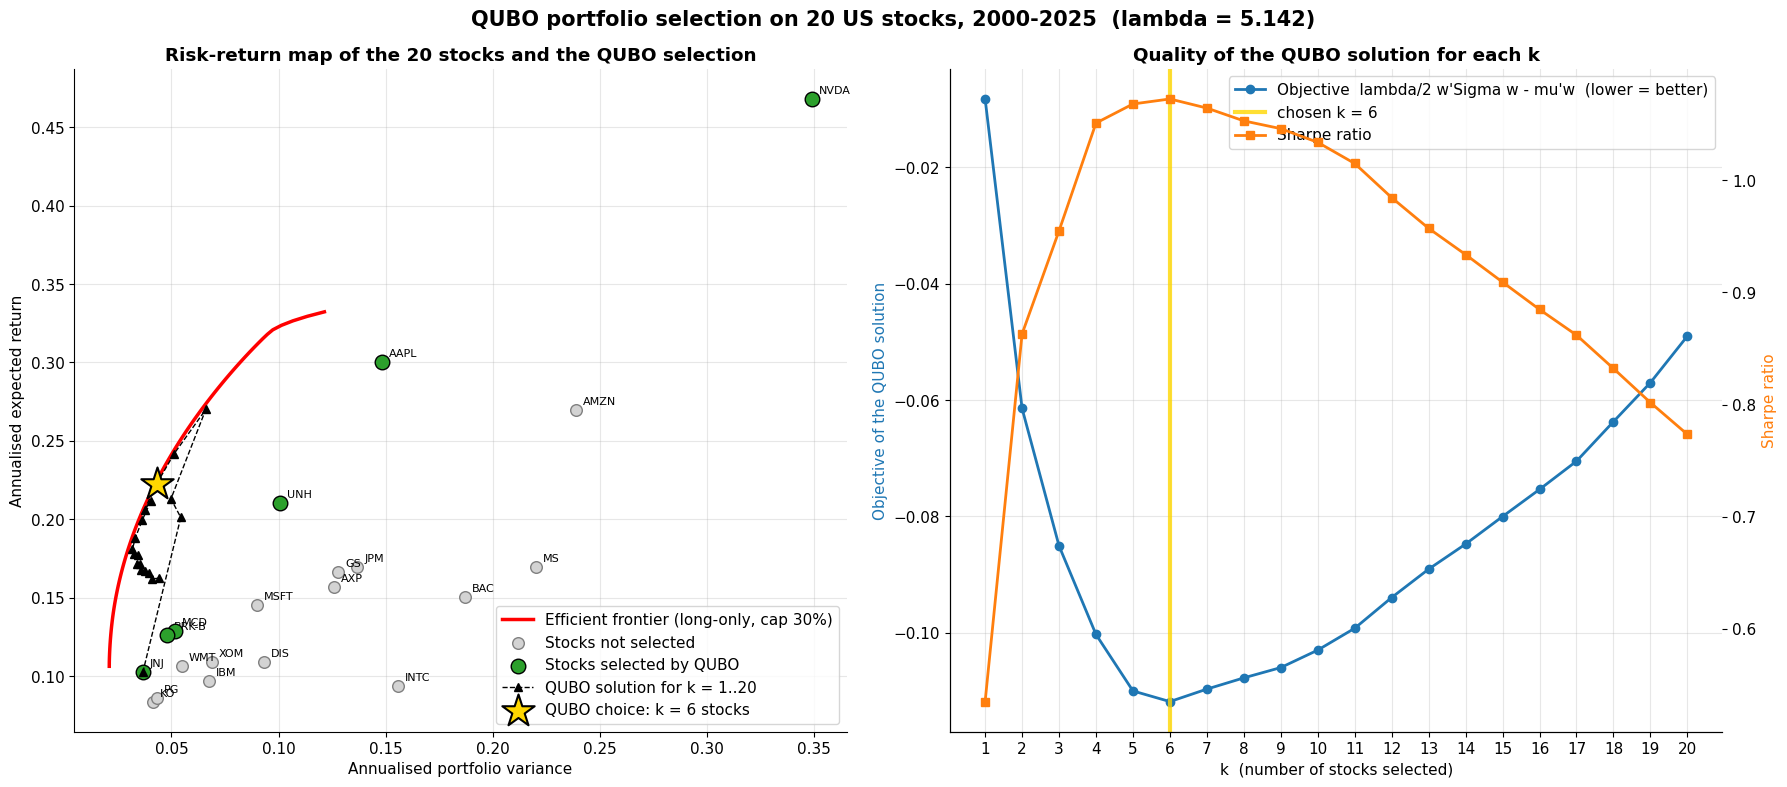

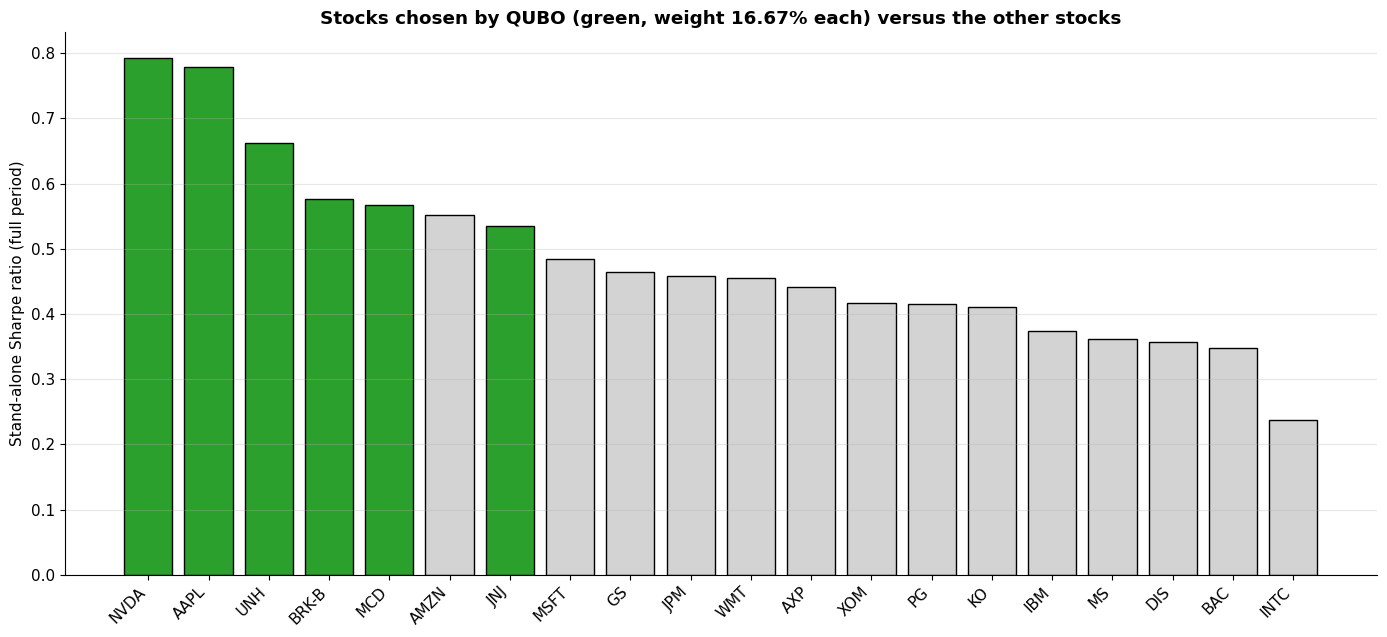

In [1]:
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.

import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

#  user settings
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

#  data 
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.

def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)

def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f



# QUBO STOCK SELECTION  |  picks the stocks of the 20 that give the best return for the risk taken
# (self-contained: nothing has to be run before this cell; needs us_stock_data/adj_close_wide.csv)
#
# Binary variable x_i = 1 if stock i is chosen; the chosen k stocks get equal weight 1/k.
#     H(x) = lambda/2 * (x'Sigma x)/k^2  -  (mu'x)/k  +  P_k * (sum(x) - k)^2           (QUBO: x'Qx + const)
#   mu, Sigma : full-period 2000-2025 annualised mean return and covariance (no train/test split, no backtest)
#   lambda    : risk aversion for which the continuous mean-variance optimum is the max-Sharpe portfolio
#               (lambda = (R_t - RF)/sigma_t^2, from mu and Sigma only)
#   P_k       : penalty from the Monte Carlo estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#   k         : the QUBO is solved for every k = 1..20 (simulated annealing + exhaustive check); the k whose QUBO
#               solution has the lowest value of the SAME risk-return objective  lambda/2 w'Sigma w - mu'w  is chosen.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K_LIST  = list(range(1, N + 1))
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

# lambda 
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")

# Monte Carlo penalty 
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
MC_P = np.zeros((MC_RUNS, len(K_LIST)))
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    q_, lin_, s_ = np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1)
    for j, k in enumerate(K_LIST):
        MC_P[run, j] = penalty_lower_bound(q_, lin_, s_, k, LAMBDA)
P_K = MC_P.max(axis=0)

#  QUBO for every k 
def build_qubo_select_P(mu, Sigma, lam, k, P):
    n = len(mu)
    Q = 0.5 * lam / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

rows, SOL = [], {}
t0 = time.time()
for j, k in enumerate(K_LIST):
    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P_K[j])
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + k))
    w, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
    z = (w > 0).astype(float)
    assert z.sum() == k and np.isclose(z @ q["Q"] @ z + q["const"], mv_objective(w, mu, Sigma, LAMBDA))
    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)
    f_sa = mv_objective(w, mu, Sigma, LAMBDA)
    ret, var, vol, sh = port_stats(w)
    SOL[k] = w
    rows.append({"k": k, "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
                 "Objective": f_sa, "Objective (exact)": f_ex,
                 "SA = exact": bool(f_sa <= f_ex + 1e-10 and set(np.flatnonzero(w)) == set(sel_ex)),
                 "P used": P_K[j]})
QK = pd.DataFrame(rows).set_index("k")
print(f"QUBO solved for k = 1..{N} in {time.time() - t0:.1f} s (annealing + exhaustive check).  "
      f"Annealing = exact optimum for all k: {bool(QK['SA = exact'].all())}\n")

#  choose k and report 
K_STAR = int(QK["Objective"].idxmin())
w_star = SOL[K_STAR]
sel = np.flatnonzero(w_star)
print("=" * 78)
print(f"QUBO RESULT: choose k = {K_STAR} of the {N} stocks, equal weight {100 / K_STAR:.2f}% each")
print("=" * 78)
stock_tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                          "Weight (%)": w_star * 100}, index=tickers)
stock_tab["Sharpe (stand-alone)"] = (mu - RF) / np.sqrt(np.diag(Sigma))
stock_tab["Selected"] = np.where(w_star > 0, "YES", "-")
display(stock_tab.sort_values(["Selected", "Weight (%)"], ascending=[False, False]).round(3))

cmp_rows = {}
for name, w_ in [(f"QUBO selection (k = {K_STAR})", w_star), ("Equal weight, all 20 stocks", w_ew),
                 ("Markowitz max-Sharpe", w_maxsh), ("Markowitz min-variance", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": mv_objective(w_, mu, Sigma, LAMBDA), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return of the QUBO selection (same mu and Sigma for every row):")
display(CMP.round(4))
print("QUBO solution for every k:")
display(QK.round(4))
QK.to_csv(f"{OUT_DIR}/qubo_selection_all_k.csv"); CMP.to_csv(f"{OUT_DIR}/qubo_selection_comparison.csv")
stock_tab.to_csv(f"{OUT_DIR}/qubo_selection_stocks.csv")

#  chart 1: risk-return map + choice of k 
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_star == 0]), mu[w_star == 0], s=70, color="lightgrey", edgecolor="grey", label="Stocks not selected", zorder=3)
ax.scatter(xs(sig2[sel]), mu[sel], s=110, color="#2ca02c", edgecolor="black", label="Stocks selected by QUBO", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
qv = np.array([port_stats(SOL[k])[1] for k in K_LIST]); qr = np.array([port_stats(SOL[k])[0] for k in K_LIST])
ax.plot(xs(qv), qr, color="black", lw=1, ls="--", marker="^", ms=6, label="QUBO solution for k = 1..20", zorder=5)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(xs(vs_), rs, marker="*", s=600, color="gold", edgecolor="black", linewidths=1.5, zorder=6,
           label=f"QUBO choice: k = {K_STAR} stocks")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map of the 20 stocks and the QUBO selection", fontweight="bold")

ax = axes[1]
ax.plot(K_LIST, QK["Objective"], color="#1f77b4", marker="o", lw=2, label="Objective  lambda/2 w'Sigma w - mu'w  (lower = better)")
ax.axvline(K_STAR, color="gold", lw=3, alpha=0.8, label=f"chosen k = {K_STAR}")
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Objective of the QUBO solution", color="#1f77b4")
ax.set_xticks(K_LIST); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, QK["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the QUBO solution for each k", fontweight="bold")
fig.suptitle(f"QUBO portfolio selection on {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_selection_riskreturn_and_k"); plt.show()

#  chart 2: the selected stocks 
order = np.argsort(-(mu - RF) / np.sqrt(sig2))
fig, ax = plt.subplots(figsize=(14, 6.5))
colors = ["#2ca02c" if w_star[i] > 0 else "lightgrey" for i in order]
ax.bar([tickers[i] for i in order], ((mu - RF) / np.sqrt(sig2))[order], color=colors, edgecolor="black")
ax.set_ylabel("Stand-alone Sharpe ratio (full period)"); ax.grid(True, axis="y", alpha=0.3)
ax.set_title(f"Stocks chosen by QUBO (green, weight {100 / K_STAR:.2f}% each) versus the other stocks", fontweight="bold")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); savefig("qubo_selection_stocks"); plt.show()

In [ ]:
import time
import numpy as np
import pandas as pd
import dimod

#  settings 
K_RUN         = [4, 5, 6]     # which k to run on hardware (each QPU run costs access time)
RUN_LOCAL_SA  = True             # free, local: ALWAYS run this first to debug
RUN_QPU       = False            # True -> real quantum annealer (uses your QPU minutes)
RUN_HYBRID    = False            # True -> Leap hybrid solver (also uses Leap time)
NUM_READS     = 1000             # annealing reads per QPU call
ANNEAL_US     = 20               # annealing time per read, microseconds
P_FLOOR       = 0.01             # on hardware never use P = 0 (noise would break the constraint)
P_SCALE       = 1.0              # try 0.5, 1, 2, 4: the penalty strength is the main tuning knob
HYBRID_TIME_S = 5                # hybrid solver time limit (seconds; the service has a minimum)
OUT_CSV       = "qubo_fullperiod_outputs/dwave_results.csv"

# QUBO -> BQM 
def to_bqm(Q, const):
    """Your Q is a full N x N matrix with energy x'Qx + const; dimod wants linear + upper-triangular terms."""
    n = Q.shape[0]
    lin = {i: float(Q[i, i]) for i in range(n)}
    quad = {(i, j): float(Q[i, j] + Q[j, i]) for i in range(n) for j in range(i + 1, n)}
    return dimod.BinaryQuadraticModel(lin, quad, float(const), dimod.BINARY)

def check_bqm(bqm, Q, const, trials=200, seed=0):
    """Same kind of check you already do: BQM energy must equal x'Qx + const for random bit strings."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        x = rng.integers(0, 2, Q.shape[0]).astype(float)
        e_bqm = bqm.energy({i: int(x[i]) for i in range(len(x))})
        assert np.isclose(e_bqm, x @ Q @ x + const, atol=1e-9), "BQM energy != QUBO energy"

def summarise(sampleset, k, Q, const, f_exact, sel_exact, label, extra=None):
    """Feasibility, hit-rate and best objective from a dimod SampleSet."""
    rec = sampleset.record
    X = np.array([[s[i] for i in range(N)] for s in sampleset.samples()], dtype=float)   # one row per read
    occ = rec.num_occurrences
    feas = X.sum(axis=1) == k
    best_obj, best_sel = np.nan, None
    hit = 0.0
    if feas.any():
        w = X[feas] / k
        objs = np.array([mv_objective(wi, mu, Sigma, LAMBDA) for wi in w])
        j = int(np.argmin(objs)); best_obj = float(objs[j]); best_sel = set(np.flatnonzero(X[feas][j]))
        hit = float(occ[feas][np.isclose(objs, f_exact, atol=1e-9)].sum() / occ.sum() * 100)
    row = {"k": k, "solver": label,
           "feasible reads (%)": float(occ[feas].sum() / occ.sum() * 100),
           "reads at exact optimum (%)": hit,
           "best objective": best_obj, "exact objective": f_exact,
           "same stocks as exact": best_sel == set(sel_exact) if best_sel is not None else False,
           "stocks": ", ".join(tickers[i] for i in sorted(best_sel)) if best_sel else ""}
    if extra:
        row.update(extra)
    return row

# solvers 
rows = []
for k in K_RUN:
    # Ensure penalty estimates exist, even if the Monte Carlo penalty cell
    # was not executed before this cell.
    if "P_K" not in globals() or len(P_K) <= max(K_RUN):
        _MC_N = globals().get("MC_N", 5000)
        _MC_RUNS = globals().get("MC_RUNS", 200)
        _MC_SEED = globals().get("MC_SEED", SEED + 7)

        def _mc_binary_samples(n, m, rng):
            cardinality = rng.integers(0, n + 1, size=m)
            ranks = np.argsort(
                np.argsort(rng.random((m, n)), axis=1), axis=1
            )
            return (ranks < cardinality[:, None]).astype(float)

        def _penalty_lower_bound(qv, linear, cardinality, k):
            objective = 0.5 * LAMBDA * qv / k**2 - linear / k
            violation = (cardinality - k) ** 2
            minimum_violation = violation.min()
            feasible_objective = objective[
                violation == minimum_violation
            ].min()

            better_invalid = (
                (objective < feasible_objective)
                & (violation > minimum_violation)
            )
            if not better_invalid.any():
                return 0.0

            return float(np.max(
                (feasible_objective - objective[better_invalid])
                / (violation[better_invalid] - minimum_violation)
            ))

        _rng = np.random.default_rng(_MC_SEED)
        P_K = np.zeros(N + 1)

        for _ in range(_MC_RUNS):
            _X = _mc_binary_samples(N, _MC_N, _rng)
            _q = np.einsum("ri,ij,rj->r", _X, Sigma, _X)
            _linear = _X @ mu
            _cardinality = _X.sum(axis=1)

            for _k in range(1, max(K_RUN) + 1):
                P_K[_k] = max(
                    P_K[_k],
                    _penalty_lower_bound(_q, _linear, _cardinality, _k),
                )

    P = max(float(P_K[k]), P_FLOOR) * P_SCALE
    def build_qubo_select_P(mu, Sigma, lam, k, P):
        mu = np.asarray(mu, dtype=float)
        Sigma = np.asarray(Sigma, dtype=float)

        if Sigma.shape != (len(mu), len(mu)):
            raise ValueError("Sigma must be square with size len(mu)")
        if k <= 0:
            raise ValueError("k must be positive")

        n = len(mu)
        Q = lam * Sigma / (2.0 * k**2)

        # Linear objective and cardinality penalty
        Q[np.diag_indices(n)] += -mu / k + P * (1.0 - 2.0 * k)

        # P * (sum(x) - k)^2
        Q += P * (np.ones((n, n)) - np.eye(n))

        const = P * k**2
        return {"Q": Q, "const": float(const)}

    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P)
    bqm = to_bqm(q["Q"], q["const"]); check_bqm(bqm, q["Q"], q["const"])
    # Exact cardinality-k reference solution
    def exact_select(mu, Sigma, lam, k):

        mu = np.asarray(mu, dtype=float)
        Sigma = np.asarray(Sigma, dtype=float)

        if Sigma.shape != (len(mu), len(mu)):
            raise ValueError("Sigma must be square with size len(mu)")
        if not 1 <= k <= len(mu):
            raise ValueError("k must be between 1 and len(mu)")

        best_obj = np.inf
        best_sel = None

        for selected in combinations(range(len(mu)), k):
            w = np.zeros(len(mu), dtype=float)
            w[list(selected)] = 1.0 / k

            obj = float(mv_objective(w, mu, Sigma, lam))
            if obj < best_obj:
                best_obj = obj
                best_sel = selected

        return best_sel, best_obj

    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)

    if RUN_LOCAL_SA:                                           # free, local simulated annealing (dwave-samplers)
        from dwave.samplers import SimulatedAnnealingSampler
        t0 = time.time()
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=NUM_READS, seed=42)
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, "Local SA (dwave-samplers)",
                              {"wall time (s)": time.time() - t0, "P used": P}))

    if RUN_QPU:                                                # real annealer
        from dwave.system import DWaveSampler, EmbeddingComposite
        from dwave.embedding.chain_strength import uniform_torque_compensation
        qpu = DWaveSampler()                                   # picks the default QPU of your account
        sampler = EmbeddingComposite(qpu)
        t0 = time.time()
        ss = sampler.sample(bqm, num_reads=NUM_READS, annealing_time=ANNEAL_US,
                            chain_strength=uniform_torque_compensation(bqm, prefactor=1.414),
                            return_embedding=True, label=f"portfolio-qubo-k{k}")
        emb = ss.info["embedding_context"]["embedding"]
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, f"QPU ({qpu.properties.get('chip_id', 'unknown')})", {
            "wall time (s)": time.time() - t0, "P used": P,
            "qpu access time (ms)": ss.info["timing"]["qpu_access_time"] / 1000,
            "physical qubits used": sum(len(c) for c in emb.values()),
            "max chain length": max(len(c) for c in emb.values()),
            "mean chain break fraction": float(np.mean(ss.record.chain_break_fraction)),
        }))

    if RUN_HYBRID:                                             # Leap hybrid solver (classical + QPU)
        from dwave.system import LeapHybridSampler
from itertools import combinations
        t0 = time.time()
        ss = LeapHybridSampler().sample(bqm, time_limit=HYBRID_TIME_S, label=f"portfolio-qubo-k{k}-hybrid")
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, "Leap hybrid",
                              {"wall time (s)": time.time() - t0, "P used": P,
                               "charged time (ms)": ss.info.get("charge_time", np.nan) / 1000}))

DW = pd.DataFrame(rows)
display(DW.round(4))
DW.to_csv(OUT_CSV, index=False)
print(f"saved {OUT_CSV}")